# URB-03 · Índice de criticidad · Versión complementaria (auditoría, noviembre 2026)

> **Copia complementaria** de `Indice_criticidad_urbana_Guayaquil_piloto.ipynb`. **El notebook original no se modifica.**

**Objetivo de esta copia:** implementar la fórmula H–E–V con los tres riesgos, dos métodos de agregación, normalización y sensibilidad de pesos sobre al menos cinco zonas sintéticas.

| Parte | Contenido | ¿Se ejecuta para la entrega? |
|---|---|---|
| **Parte C** (a continuación) | Bloque nuevo y autocontenido que cubre los ajustes de la auditoría | **Sí.** Ejecutar desde la celda C.0 hasta el final de la Parte C |
| **Parte B** | Copia del notebook original con ajustes puntuales marcados `# [AJUSTE AUDITORÍA]` | No es necesaria (referencia) |

**Cómo ejecutar:** ver `README_COMPLEMENTARIO.md` en la carpeta del proyecto. En Colab, poner `CLONAR_REPO = True` en la celda C.0 para que los datos de prueba y `COMUN/` se descarguen del repositorio.
Las salidas se guardan en `salidas_complementarias/`.

**Datos:** cada tabla indica `tipo_dato` (`real` / `derivado_real` / `sintetico` / `pendiente`). Los resultados sintéticos **no** deben presentarse como validación real.


# Parte C · Bloque complementario URB-03 (entrega mínima de la auditoría)

**Qué resuelve esta parte:**

1. Presenta una **formulación H–E–V inequívoca** del índice de criticidad para los **tres riesgos**: accidentes viales, seguridad urbana e inundaciones.
2. Implementa **dos normalizaciones** (min-max y z-score con transformación normal) y **dos métodos de agregación** (aditiva ponderada y multiplicativa geométrica).
3. Calcula los resultados sobre **12 zonas sintéticas** (el mínimo exigido es 5). Son las zonas comunes `PER-Z01…Z12` con valores **sintéticos**.
4. Hace un **análisis de sensibilidad** de pesos de ±10 %, ±20 % y ±30 % y entrega la **tabla de pesos**, el **documento matemático** y la comparación.

> Los resultados de esta parte **no** describen la Perimetral real: verifican que la fórmula y el código funcionan.
> Para aplicar el índice a las observaciones de URB-01 (que mezclan datos reales y sintéticos), cambiar `ORIGEN_DATOS = "urb01"` en C.2.

Dependencias: `numpy`, `pandas`, `scipy`, `matplotlib`.

In [1]:
# ===================== C.0 · Base común (idéntica en todos los notebooks complementarios) =====================
# Fuente de verdad: GEMELO DIGITAL/COMUN (contrato_hev_v1.json, zonas_perimetral.*). Si el repositorio no está
# disponible (p. ej. Colab sin clonar), se usa la tabla de zonas embebida más abajo, que es una copia exacta.
import json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

SEMILLA = 42
rng_c = np.random.default_rng(SEMILLA)

CLONAR_REPO = False          # True en Google Colab para descargar COMUN/ y los datos de prueba del repositorio
URL_REPO = "https://github.com/AaronTech24/Gemelos_Digitales.git"

def buscar_raiz_repo():
    """Devuelve la carpeta 'GEMELO DIGITAL' del repositorio, o None si no se encuentra."""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "COMUN" / "contrato_hev_v1.json").exists():
            return q
        if (q / "GEMELO DIGITAL" / "COMUN" / "contrato_hev_v1.json").exists():
            return q / "GEMELO DIGITAL"
    for q in [Path("/content/Gemelos_Digitales/GEMELO DIGITAL")]:
        if (q / "COMUN").exists():
            return q
    return None

RAIZ = buscar_raiz_repo()
if RAIZ is None and CLONAR_REPO:
    subprocess.run(["git", "clone", "--depth", "1", URL_REPO, "/content/Gemelos_Digitales"], check=False)
    RAIZ = buscar_raiz_repo()

def ruta_dato(*partes):
    """Ruta a un archivo del repositorio (relativa a 'GEMELO DIGITAL') o None si no existe."""
    if RAIZ is None:
        return None
    r = RAIZ.joinpath(*partes)
    return r if r.exists() else None

# --- Zonas comunes de la Vía Perimetral (COMUN/zonas_perimetral.csv, regla v1) ---
LAT_NORTE, LAT_SUR, N_ZONAS = -2.0730, -2.2425, 12
BUFFER_CORREDOR_M = 200
_COLS_Z = ["id_zona", "lat_max", "lat_min", "centroide_lat", "centroide_lon", "area_km2",
           "longitud_eje_km", "vel_max_osm_kmh", "carriles_osm"]
ZONAS_EMBEBIDAS = [
    ('PER-Z01', -2.073, -2.087125, -2.080262, -79.93277, 1.491, 3.88, 90, 3),
    ('PER-Z02', -2.087125, -2.10125, -2.094077, -79.947805, 0.662, 1.59, 90, 3),
    ('PER-Z03', -2.10125, -2.115375, -2.108339, -79.947903, 0.68, 2.29, 90, 3),
    ('PER-Z04', -2.115375, -2.1295, -2.122392, -79.948995, 0.713, 3.22, 60, 3),
    ('PER-Z05', -2.1295, -2.143625, -2.136494, -79.94695, 0.674, 1.62, 90, 3),
    ('PER-Z06', -2.143625, -2.15775, -2.15081, -79.94666, 0.675, 1.61, 90, 3),
    ('PER-Z07', -2.15775, -2.171875, -2.164975, -79.947666, 0.688, 1.65, 90, 3),
    ('PER-Z08', -2.171875, -2.186, -2.179743, -79.947688, 0.798, 1.92, 90, 3),
    ('PER-Z09', -2.186, -2.200125, -2.192248, -79.957006, 0.789, 1.87, 90, 3),
    ('PER-Z10', -2.200125, -2.21425, -2.207136, -79.956081, 0.664, 1.59, 90, 3),
    ('PER-Z11', -2.21425, -2.228375, -2.221591, -79.956534, 0.691, 1.65, 90, 3),
    ('PER-Z12', -2.228375, -2.2425, -2.235703, -79.933396, 2.147, 7.73, 90, 3)
]

def cargar_zonas():
    r = ruta_dato("COMUN", "zonas_perimetral.csv")
    if r is not None:
        z = pd.read_csv(r)
        z["origen_tabla"] = "COMUN/zonas_perimetral.csv"
    else:
        z = pd.DataFrame(ZONAS_EMBEBIDAS, columns=_COLS_Z)
        z["origen_tabla"] = "tabla embebida (copia de COMUN v1)"
    return z

ZONAS = cargar_zonas()
IDS_ZONA = ZONAS["id_zona"].tolist()

def asignar_zona(lat):
    """Regla común: franja de latitud (norte -> sur). Devuelve NaN fuera del rango del corredor."""
    lat = pd.Series(np.atleast_1d(lat), dtype=float)
    k = np.floor((LAT_NORTE - lat) / ((LAT_NORTE - LAT_SUR) / N_ZONAS))
    k = k.where((k >= 0) & (k < N_ZONAS))
    return k.map(lambda i: f"PER-Z{int(i) + 1:02d}" if pd.notna(i) else None).values

CORTES_NIVEL = [0.25, 0.50, 0.75]
def nivel(x):
    return pd.cut(pd.Series(x, dtype=float), [-np.inf, *CORTES_NIVEL, np.inf], right=False,
                  labels=["bajo", "medio", "alto", "critico"]).astype(str).values

# --- Cargador común de eventos reales (siniestros ATM y homicidios), con deduplicación documentada ---
_VEHICULOS = ["AUTOMOVIL", "BICICLETA", "BUS", "CAMION", "CAMIONETA", "EMERGENCIAS", "ESPECIAL", "FURGONETA",
              "MOTOCICLETA", "NO_IDENTIFICADO", "SCOOTER_ELECTRICO", "TRICIMOTO", "VEHICULO_DEPORTIVO_UTILITARIO"]

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def cargar_eventos_reales():
    """Devuelve (EVENTOS, CALIDAD) en el esquema 'evento' del contrato. No inventa nada si faltan archivos.

    Regla de deduplicación ATM: la unidad es el código SINIESTROS. En el CSV filtrado, 1 080 filas son duplicados
    exactos y otras repiten el código cambiando solo columnas de vehículos; se conserva 1 fila por código y los
    vehículos se combinan con el máximo (presencia del tipo de vehículo en el siniestro).
    """
    eventos, calidad = [], []
    r_acc = ruta_dato("URB-04", "test_Data", "siniestros_via_perimetral_guayaquil.csv")
    r_hom = ruta_dato("URB-04", "test_Data", "homicidios_via_perimetral.csv")
    if r_acc is not None:
        a = pd.read_csv(r_acc, sep=";", encoding="utf-8-sig", dtype=str)
        n0 = len(a)
        dup_exactos = int(a.drop(columns=["id"]).duplicated().sum())
        for c in _VEHICULOS:
            a[c] = _num(a[c]).fillna(0)
        veh = a.groupby("SINIESTROS")[_VEHICULOS].max()
        a = a.drop_duplicates("SINIESTROS").set_index("SINIESTROS").drop(columns=_VEHICULOS).join(veh).reset_index()
        les, fal = _num(a.LESIONADOS).fillna(0).astype(int), _num(a.FALLECIDOS).fillna(0).astype(int)
        ev = pd.DataFrame({
            "id_evento": a.SINIESTROS, "riesgo": "accidentes_viales",
            "fecha_hora": pd.to_datetime(a.FECHA + " " + a.HORA, format="%d/%m/%Y %H:%M:%S", errors="coerce"),
            "lat": _num(a.LATITUD_Y), "lon": _num(a.LONGITUD_X), "subtipo": a.TIPO_DE_SINIESTRO,
            # severidad 1-4 (contrato): 4 con fallecidos · 3 con >= 3 lesionados · 2 con lesionados · 1 sin víctimas
            "severidad": np.select([fal > 0, les >= 3, les > 0], [4, 3, 2], 1),
            "lesionados": les, "fallecidos": fal, "motocicleta": a.MOTOCICLETA > 0,
            "arma_fuego": np.nan, "causa": a.CAUSA_PROBABLE, "feriado": a.FERIADO.eq("SI"),
            "via_osm_id": a.via_osm_id, "fuente": "F01 ATM", "tipo_dato": "real"})
        calidad.append({"riesgo": "accidentes_viales", "filas_csv": n0, "duplicados_exactos": dup_exactos,
                        "filas_extra_mismo_codigo": n0 - dup_exactos - len(ev), "eventos_unicos": len(ev)})
        eventos.append(ev)
    if r_hom is not None:
        h = pd.read_csv(r_hom, encoding="utf-8-sig", dtype=str)
        ev = pd.DataFrame({
            "id_evento": "HOM-" + h["id"].str.zfill(4), "riesgo": "seguridad_urbana",
            "fecha_hora": pd.to_datetime(h.fecha.str[:10] + " " + h.hora_infraccion.fillna("00:00:00"), errors="coerce"),
            "lat": _num(h.coordenada_y), "lon": _num(h.coordenada_x), "subtipo": h.tipo_muerte,
            "severidad": 4, "lesionados": 0, "fallecidos": 1, "motocicleta": np.nan,
            "arma_fuego": h.arma.str.contains("fuego", case=False, na=False), "causa": h.presunta_motivacion,
            "feriado": np.nan, "via_osm_id": h.via_osm_id, "fuente": "F02 homicidios", "tipo_dato": "real"})
        calidad.append({"riesgo": "seguridad_urbana", "filas_csv": len(h),
                        "duplicados_exactos": int(h.drop(columns=["id"]).duplicated().sum()),
                        "filas_extra_mismo_codigo": 0, "eventos_unicos": len(ev)})
        eventos.append(ev)
    if not eventos:
        return pd.DataFrame(columns=["id_evento", "riesgo", "fecha_hora", "lat", "lon", "id_zona"]), pd.DataFrame()
    E = pd.concat(eventos, ignore_index=True)
    E["id_zona"] = asignar_zona(E["lat"])
    C = pd.DataFrame(calidad).set_index("riesgo")
    C["fecha_invalida"] = E.groupby("riesgo").fecha_hora.apply(lambda s: int(s.isna().sum()))
    C["coordenada_invalida"] = E.groupby("riesgo").apply(lambda g: int(g[["lat", "lon"]].isna().any(axis=1).sum()))
    C["fuera_del_corredor"] = E.groupby("riesgo").id_zona.apply(lambda s: int(s.isna().sum()))
    C["desde"] = E.groupby("riesgo").fecha_hora.min()
    C["hasta"] = E.groupby("riesgo").fecha_hora.max()
    # Homicidios antes de 2023: <= 10 por año en la base -> cobertura incompleta; se excluyen de los indicadores.
    E["usar_en_indicadores"] = ~((E.riesgo == "seguridad_urbana") & (E.fecha_hora.dt.year < 2023))
    return E.dropna(subset=["id_zona"]).reset_index(drop=True), C.reset_index()

SALIDA_C = Path("salidas_complementarias")
SALIDA_C.mkdir(exist_ok=True)

print("Repositorio encontrado:", RAIZ if RAIZ else "NO (se usan tablas embebidas / datos sintéticos)")
print("Zonas comunes:", len(ZONAS), "|", ZONAS["origen_tabla"].iloc[0], "| salidas ->", SALIDA_C.resolve())

Repositorio encontrado: /home/claude/gemelos_digitales/GEMELO DIGITAL
Zonas comunes: 12 | COMUN/zonas_perimetral.csv | salidas -> /home/claude/gemelos_digitales/GEMELO DIGITAL/URB-03/src/salidas_complementarias


## C.1 · Formulación matemática

**Notación.** $z$ = zona, $r \in \{\text{ACC}, \text{SEG}, \text{INU}\}$ = riesgo, $c \in \{H, E, V\}$ = componente, $j$ = variable. $J_{r,c}$ es el conjunto de variables del riesgo $r$ y el componente $c$ (matriz de URB-01, `COMUN/matriz_variables_hev.csv`).

**1. Normalización** de cada variable $x_{z,j}$ a $[0,1]$. Si la variable tiene sentido negativo (−), se usa $1-\tilde x$.

* N1, min-max: $\tilde x_{z,j} = \dfrac{x_{z,j} - \min_z x_{z,j}}{\max_z x_{z,j} - \min_z x_{z,j}}$
* N2, z-score con transformación normal: $\tilde x_{z,j} = \Phi\!\left(\dfrac{x_{z,j} - \bar x_j}{s_j}\right)$, donde $\Phi$ es la función de distribución normal estándar. Acota a $(0,1)$ sin que el máximo y el mínimo dominen.

**2. Componentes** (promedio simple dentro de cada componente):
$$H_{z,r} = \frac{1}{|J_{r,H}|}\sum_{j\in J_{r,H}} \tilde x_{z,j},\qquad E_{z,r},\ V_{z,r}\ \text{análogos}$$

**3. Índice por riesgo.** Hay dos métodos de agregación, con pesos $w_H + w_E + w_V = 1$:

* **A, aditiva ponderada (compensatoria):** $R^{A}_{z,r} = w_H H_{z,r} + w_E E_{z,r} + w_V V_{z,r}$
* **B, multiplicativa geométrica (no compensatoria):** $R^{B}_{z,r} = \max(H_{z,r},\varepsilon)^{w_H}\cdot \max(E_{z,r},\varepsilon)^{w_E}\cdot \max(V_{z,r},\varepsilon)^{w_V}$, con $\varepsilon = 0{,}01$

B sigue la noción de riesgo de UNDRR (riesgo = peligro × exposición × vulnerabilidad): si un componente es bajo, el riesgo baja aunque los otros sean altos. A, en cambio, permite que un componente alto compense a otro bajo.

**4. Índice global de criticidad:** $IC^{m}_{z} = \sum_r \alpha_r R^{m}_{z,r}$, con $\sum_r \alpha_r = 1$ y $m \in \{A, B\}$.

**5. Nivel** (contrato común): bajo < 0,25 ≤ medio < 0,50 ≤ alto < 0,75 ≤ crítico.

**Pesos base:** $w_H = w_E = w_V = 1/3$ y $\alpha_r = 1/3$. Son pesos **neutrales provisionales**, porque aún no hay una ponderación validada por expertos (AHP o Delphi). La sensibilidad de C.5 mide cuánto depende el ranking de esta elección.

In [2]:
from scipy.stats import norm, spearmanr
import matplotlib.pyplot as plt

r_m = ruta_dato("COMUN", "matriz_variables_hev.csv")
if r_m is not None:
    MATRIZ = pd.read_csv(r_m, encoding="utf-8-sig")
else:   # copia mínima embebida de la matriz de URB-01
    MATRIZ = pd.DataFrame([v.split("|") for v in """ACC_H_tasa_siniestros_km|accidentes_viales|H|+
ACC_H_vel_max_kmh|accidentes_viales|H|+
ACC_E_tpda_veh_dia|accidentes_viales|E|+
ACC_E_poblacion_corredor|accidentes_viales|E|+
ACC_V_pct_atropellos|accidentes_viales|V|+
ACC_V_pct_motocicleta|accidentes_viales|V|+
ACC_V_tasa_letalidad|accidentes_viales|V|+
SEG_H_homicidios_km2_anio|seguridad_urbana|H|+
SEG_H_pct_arma_fuego|seguridad_urbana|H|+
SEG_E_densidad_poblacional|seguridad_urbana|E|+
SEG_E_pois_comerciales|seguridad_urbana|E|+
SEG_V_iluminacion_deficiente_pct|seguridad_urbana|V|+
SEG_V_pobreza_nbi_pct|seguridad_urbana|V|+
INU_H_precip_max_24h_mm|inundaciones|H|+
INU_H_elevacion_media_m|inundaciones|H|-
INU_E_poblacion_cota_baja|inundaciones|E|+
INU_E_via_inundable_km|inundaciones|E|+
INU_V_deficit_drenaje_pct|inundaciones|V|+
INU_V_vivienda_precaria_pct|inundaciones|V|+""".splitlines()], columns=["id_variable", "riesgo", "componente", "sentido"])
RIESGOS = ["accidentes_viales", "seguridad_urbana", "inundaciones"]
COMPS = ["H", "E", "V"]
PESOS_BASE = {"w": {"H": 1 / 3, "E": 1 / 3, "V": 1 / 3}, "alpha": {r: 1 / 3 for r in RIESGOS}}
EPS = 0.01
display(MATRIZ.pivot_table(index="riesgo", columns="componente", values="id_variable", aggfunc=lambda s: ", ".join(s)))

componente,E,H,V
riesgo,,,
accidentes_viales,"ACC_E_tpda_veh_dia, ACC_E_poblacion_corredor","ACC_H_tasa_siniestros_km, ACC_H_vel_max_kmh","ACC_V_pct_atropellos, ACC_V_pct_motocicleta, A..."
inundaciones,"INU_E_poblacion_cota_baja, INU_E_via_inundable_km","INU_H_precip_max_24h_mm, INU_H_elevacion_media_m","INU_V_deficit_drenaje_pct, INU_V_vivienda_prec..."
seguridad_urbana,"SEG_E_densidad_poblacional, SEG_E_pois_comerci...","SEG_H_homicidios_km2_anio, SEG_H_pct_arma_fuego","SEG_V_iluminacion_deficiente_pct, SEG_V_pobrez..."


## C.2 · Datos de entrada: 12 zonas sintéticas (≥ 5)

El generador crea un perfil latente por zona y riesgo, y a partir de él las variables con ruido. Así las zonas tienen diferencias coherentes, por ejemplo una zona con mucha peligrosidad vial tiene tasas altas de siniestros y de atropellos.
Todos los valores son `tipo_dato = sintetico` (semilla 42).

In [3]:
ORIGEN_DATOS = "sintetico"        # "sintetico" (entrega) | "urb01" (observaciones de URB-01, mezcla real + sintético)

RANGOS = {   # (mínimo, máximo) plausibles por variable para el generador
    "ACC_H_tasa_siniestros_km": (1, 20), "ACC_H_vel_max_kmh": (50, 90), "ACC_E_tpda_veh_dia": (20000, 80000),
    "ACC_E_poblacion_corredor": (1000, 20000), "ACC_V_pct_atropellos": (0, 40), "ACC_V_pct_motocicleta": (5, 50),
    "ACC_V_tasa_letalidad": (0, 25), "SEG_H_homicidios_km2_anio": (0, 30), "SEG_H_pct_arma_fuego": (40, 95),
    "SEG_E_densidad_poblacional": (2000, 15000), "SEG_E_pois_comerciales": (5, 80), "SEG_V_iluminacion_deficiente_pct": (5, 70),
    "SEG_V_pobreza_nbi_pct": (10, 75), "INU_H_precip_max_24h_mm": (60, 150), "INU_H_elevacion_media_m": (2, 45),
    "INU_E_poblacion_cota_baja": (0, 12000), "INU_E_via_inundable_km": (0, 3), "INU_V_deficit_drenaje_pct": (5, 80),
    "INU_V_vivienda_precaria_pct": (2, 60)}

def generar_zonas_sinteticas(ids, semilla=SEMILLA):
    r = np.random.default_rng(semilla)
    latente = {(z, rg): r.beta(2, 2) for z in ids for rg in RIESGOS}            # perfil de riesgo de cada zona
    filas = []
    for z in ids:
        f = {"id_zona": z}
        for v in MATRIZ.itertuples():
            lo, hi = RANGOS[v.id_variable]
            u = np.clip(0.7 * latente[(z, v.riesgo)] + 0.3 * r.random(), 0, 1)
            u = 1 - u if v.sentido == "-" else u                                  # elevación: alta latente -> cota baja
            f[v.id_variable] = round(lo + u * (hi - lo), 3)
        filas.append(f)
    return pd.DataFrame(filas).set_index("id_zona")

if ORIGEN_DATOS == "urb01" and ruta_dato("URB-01", "src", "salidas_complementarias", "urb01_observaciones_zona_ancha.csv"):
    X = pd.read_csv(ruta_dato("URB-01", "src", "salidas_complementarias", "urb01_observaciones_zona_ancha.csv"), index_col=0)
    TIPO_DATO = "mixto"
else:
    X = generar_zonas_sinteticas(IDS_ZONA)
    TIPO_DATO = "sintetico"
X = X[MATRIZ.id_variable]
assert len(X) >= 5, "Se requieren al menos cinco zonas"
print(f"Zonas: {len(X)} · variables: {X.shape[1]} · tipo_dato = {TIPO_DATO}")
X.round(1)

Zonas: 12 · variables: 19 · tipo_dato = sintetico


,ACC_H_tasa_siniestros_km,ACC_H_vel_max_kmh,ACC_E_tpda_veh_dia,ACC_E_poblacion_corredor,ACC_V_pct_atropellos,ACC_V_pct_motocicleta,ACC_V_tasa_letalidad,SEG_H_homicidios_km2_anio,SEG_H_pct_arma_fuego,SEG_E_densidad_poblacional,SEG_E_pois_comerciales,SEG_V_iluminacion_deficiente_pct,SEG_V_pobreza_nbi_pct,INU_H_precip_max_24h_mm,INU_H_elevacion_media_m,INU_E_poblacion_cota_baja,INU_E_via_inundable_km,INU_V_deficit_drenaje_pct,INU_V_vivienda_precaria_pct
id_zona,,,,,,,,,,,,,,,,,,,
PER-Z01,9.1,62.1,52704.3,11754.6,13.6,25.9,8.2,17.1,65.0,9372.8,49.1,44.0,36.1,124.9,22.9,5487.0,1.8,46.8,42.3
PER-Z02,12.5,68.3,58876.9,9537.7,20.7,24.7,16.1,15.8,67.0,9897.2,63.1,53.4,55.6,132.2,10.5,8285.3,1.9,62.5,44.5
PER-Z03,10.1,65.7,55308.6,9420.4,25.8,24.7,10.0,13.7,53.9,5389.0,34.0,35.5,27.3,109.5,15.3,8976.7,1.8,42.5,28.7
PER-Z04,13.4,74.9,67183.6,12773.3,29.4,40.6,18.9,9.0,66.4,7901.7,39.6,23.1,28.0,118.5,23.9,5544.0,1.6,47.8,40.2
PER-Z05,13.8,84.5,55577.7,15289.2,31.0,32.8,15.7,13.4,73.6,8494.7,50.1,41.5,40.0,126.6,23.1,6452.2,2.3,60.8,35.3
PER-Z06,9.4,68.6,52653.5,9831.9,16.3,22.8,10.3,12.0,65.6,6431.8,25.9,22.9,37.9,107.5,31.5,3639.8,1.4,29.5,32.8
PER-Z07,10.9,68.9,62314.2,10093.5,20.6,26.4,11.6,11.3,61.3,7491.9,34.0,40.6,47.3,114.3,20.0,7634.6,2.2,60.5,30.9
PER-Z08,6.3,61.9,38067.9,8556.0,14.0,15.8,8.5,19.3,68.4,11573.5,42.6,54.6,43.5,107.1,21.7,6771.4,1.5,42.8,28.9
PER-Z09,14.0,69.7,56795.0,12527.2,28.4,31.6,14.2,19.0,68.7,8290.4,48.9,41.9,43.3,82.1,34.5,2796.6,0.7,30.5,15.0


## C.3 · Normalización (N1 min-max y N2 z-score con Φ)

In [4]:
def normalizar(X, metodo):
    if metodo == "minmax":
        rango = (X.max() - X.min()).replace(0, np.nan)
        N = ((X - X.min()) / rango).fillna(0.5)
    elif metodo == "zscore":
        N = pd.DataFrame(norm.cdf((X - X.mean()) / X.std(ddof=0).replace(0, np.nan)), index=X.index, columns=X.columns).fillna(0.5)
    else:
        raise ValueError(metodo)
    neg = MATRIZ.loc[MATRIZ.sentido == "-", "id_variable"]
    N[neg] = 1 - N[neg]
    return N

NORM = {m: normalizar(X, m) for m in ["minmax", "zscore"]}
assert all(((N >= 0) & (N <= 1)).all().all() for N in NORM.values())
NORM["minmax"].round(2).head()

,ACC_H_tasa_siniestros_km,ACC_H_vel_max_kmh,ACC_E_tpda_veh_dia,ACC_E_poblacion_corredor,ACC_V_pct_atropellos,ACC_V_pct_motocicleta,ACC_V_tasa_letalidad,SEG_H_homicidios_km2_anio,SEG_H_pct_arma_fuego,SEG_E_densidad_poblacional,SEG_E_pois_comerciales,SEG_V_iluminacion_deficiente_pct,SEG_V_pobreza_nbi_pct,INU_H_precip_max_24h_mm,INU_H_elevacion_media_m,INU_E_poblacion_cota_baja,INU_E_via_inundable_km,INU_V_deficit_drenaje_pct,INU_V_vivienda_precaria_pct
id_zona,,,,,,,,,,,,,,,,,,,
PER-Z01,0.30,0.07,0.51,0.49,0.31,0.49,0.31,0.53,0.33,0.64,0.62,0.66,0.27,0.82,0.48,0.45,0.69,0.66,0.80
PER-Z02,0.66,0.33,0.72,0.16,0.59,0.45,0.82,0.44,0.39,0.73,1.00,0.96,0.86,0.97,0.90,0.89,0.72,1.00,0.86
PER-Z03,0.40,0.22,0.60,0.15,0.79,0.45,0.43,0.31,0.00,0.00,0.22,0.40,0.00,0.53,0.73,1.00,0.68,0.56,0.45
PER-Z04,0.76,0.60,1.00,0.63,0.94,1.00,1.00,0.00,0.38,0.41,0.37,0.01,0.02,0.70,0.44,0.46,0.53,0.68,0.75
PER-Z05,0.80,1.00,0.61,1.00,1.00,0.73,0.79,0.29,0.59,0.50,0.65,0.59,0.38,0.86,0.47,0.60,0.93,0.96,0.62


## C.4 · Componentes H, E, V, índice por riesgo e índice global (dos agregaciones)

In [5]:
def componentes(N):
    out = {}
    for rg in RIESGOS:
        for c in COMPS:
            cols = MATRIZ[(MATRIZ.riesgo == rg) & (MATRIZ.componente == c)].id_variable
            out[(rg, c)] = N[cols].mean(axis=1)
    return pd.DataFrame(out)

def indice(C, pesos, metodo):
    w = pd.Series(pesos["w"]); w = w / w.sum()
    a = pd.Series(pesos["alpha"]); a = a / a.sum()
    R = pd.DataFrame(index=C.index)
    for rg in RIESGOS:
        if metodo == "aditiva":
            R[rg] = sum(w[c] * C[(rg, c)] for c in COMPS)
        elif metodo == "multiplicativa":
            R[rg] = np.prod([np.maximum(C[(rg, c)], EPS) ** w[c] for c in COMPS], axis=0)
        else:
            raise ValueError(metodo)
    R["global"] = sum(a[rg] * R[rg] for rg in RIESGOS)
    return R

COMP = {n: componentes(N) for n, N in NORM.items()}
RES = {(n, m): indice(COMP[n], PESOS_BASE, m) for n in NORM for m in ["aditiva", "multiplicativa"]}

base = RES[("minmax", "aditiva")]
tabla = pd.DataFrame({f"IC_{m[:4]}_{n}": RES[(n, m)]["global"] for (n, m) in RES}).round(3)
tabla["rank_A_minmax"] = tabla["IC_adit_minmax"].rank(ascending=False).astype(int)
tabla["rank_B_minmax"] = tabla["IC_mult_minmax"].rank(ascending=False).astype(int)
tabla["nivel_A_minmax"] = nivel(tabla["IC_adit_minmax"])
tabla = tabla.sort_values("rank_A_minmax")
display(tabla)

comb = list(RES)
rho = pd.DataFrame([[spearmanr(RES[i]["global"], RES[j]["global"])[0] for j in comb] for i in comb],
                   index=[f"{m}/{n}" for n, m in comb], columns=[f"{m}/{n}" for n, m in comb]).round(3)
print("Correlación de Spearman entre los rankings globales de las 4 combinaciones (normalización × agregación):")
display(rho)
top3 = {f"{m}/{n}": list(RES[(n, m)]["global"].nlargest(3).index) for n, m in comb}
print("Top-3 zonas por combinación:", top3)

,IC_adit_minmax,IC_mult_minmax,IC_adit_zscore,IC_mult_zscore,rank_A_minmax,rank_B_minmax,nivel_A_minmax
id_zona,,,,,,,
PER-Z10,0.719,0.714,0.711,0.707,1,1,alto
PER-Z02,0.712,0.697,0.710,0.699,2,2,alto
PER-Z05,0.696,0.694,0.691,0.690,3,3,alto
PER-Z04,0.538,0.501,0.543,0.526,4,6,alto
PER-Z07,0.526,0.509,0.509,0.489,5,4,alto
PER-Z11,0.519,0.505,0.504,0.499,6,5,alto
PER-Z01,0.504,0.492,0.498,0.484,7,7,alto
PER-Z08,0.438,0.419,0.426,0.423,8,9,medio
PER-Z09,0.436,0.427,0.453,0.451,9,8,medio


Correlación de Spearman entre los rankings globales de las 4 combinaciones (normalización × agregación):


,aditiva/minmax,multiplicativa/minmax,aditiva/zscore,multiplicativa/zscore
aditiva/minmax,1.000,0.972,0.986,0.979
multiplicativa/minmax,0.972,1.000,0.972,0.965
aditiva/zscore,0.986,0.972,1.000,0.993
multiplicativa/zscore,0.979,0.965,0.993,1.000


Top-3 zonas por combinación: {'aditiva/minmax': ['PER-Z10', 'PER-Z02', 'PER-Z05'], 'multiplicativa/minmax': ['PER-Z10', 'PER-Z02', 'PER-Z05'], 'aditiva/zscore': ['PER-Z10', 'PER-Z02', 'PER-Z05'], 'multiplicativa/zscore': ['PER-Z10', 'PER-Z02', 'PER-Z05']}


**Cómo leer la comparación.** Si las cuatro combinaciones tienen $\rho \ge 0{,}9$ y comparten las primeras zonas, la prioridad no depende del método. Las diferencias entre A y B aparecen en las zonas con un componente muy bajo: la agregación multiplicativa las baja más, porque no permite compensar.

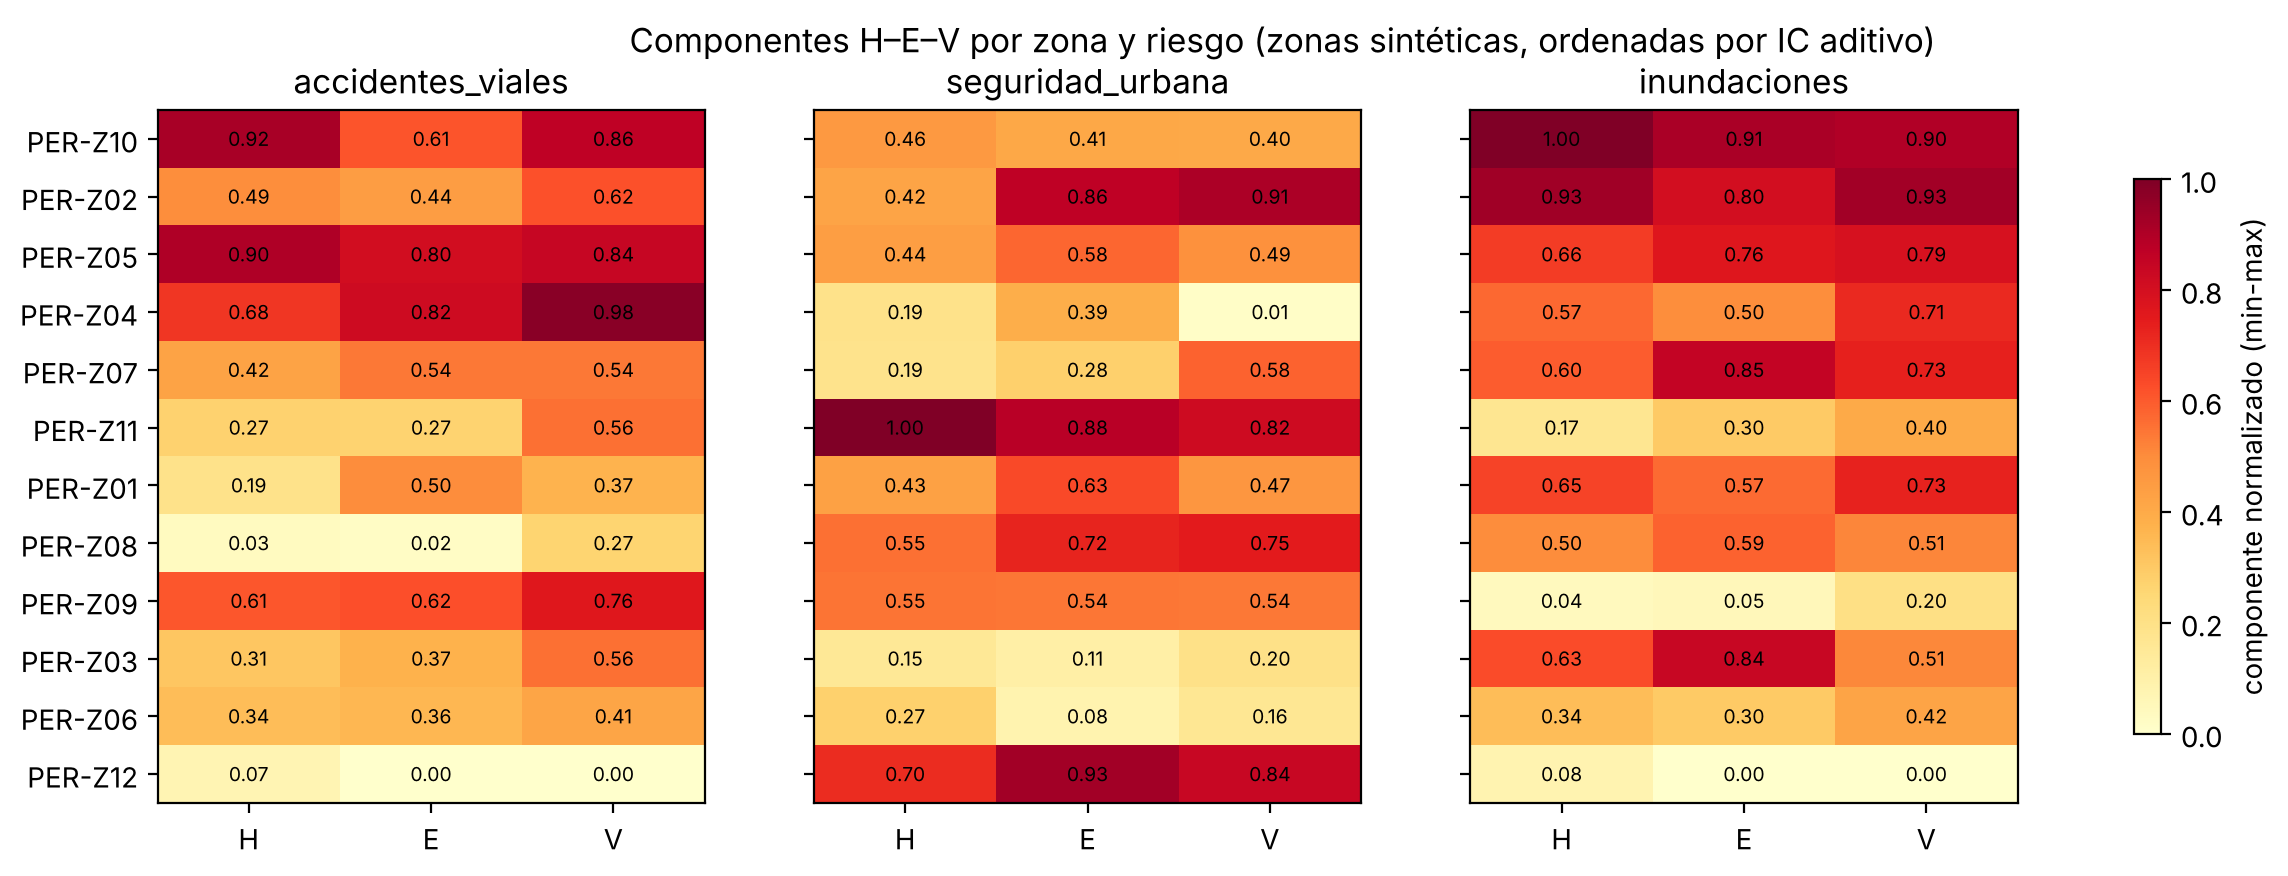

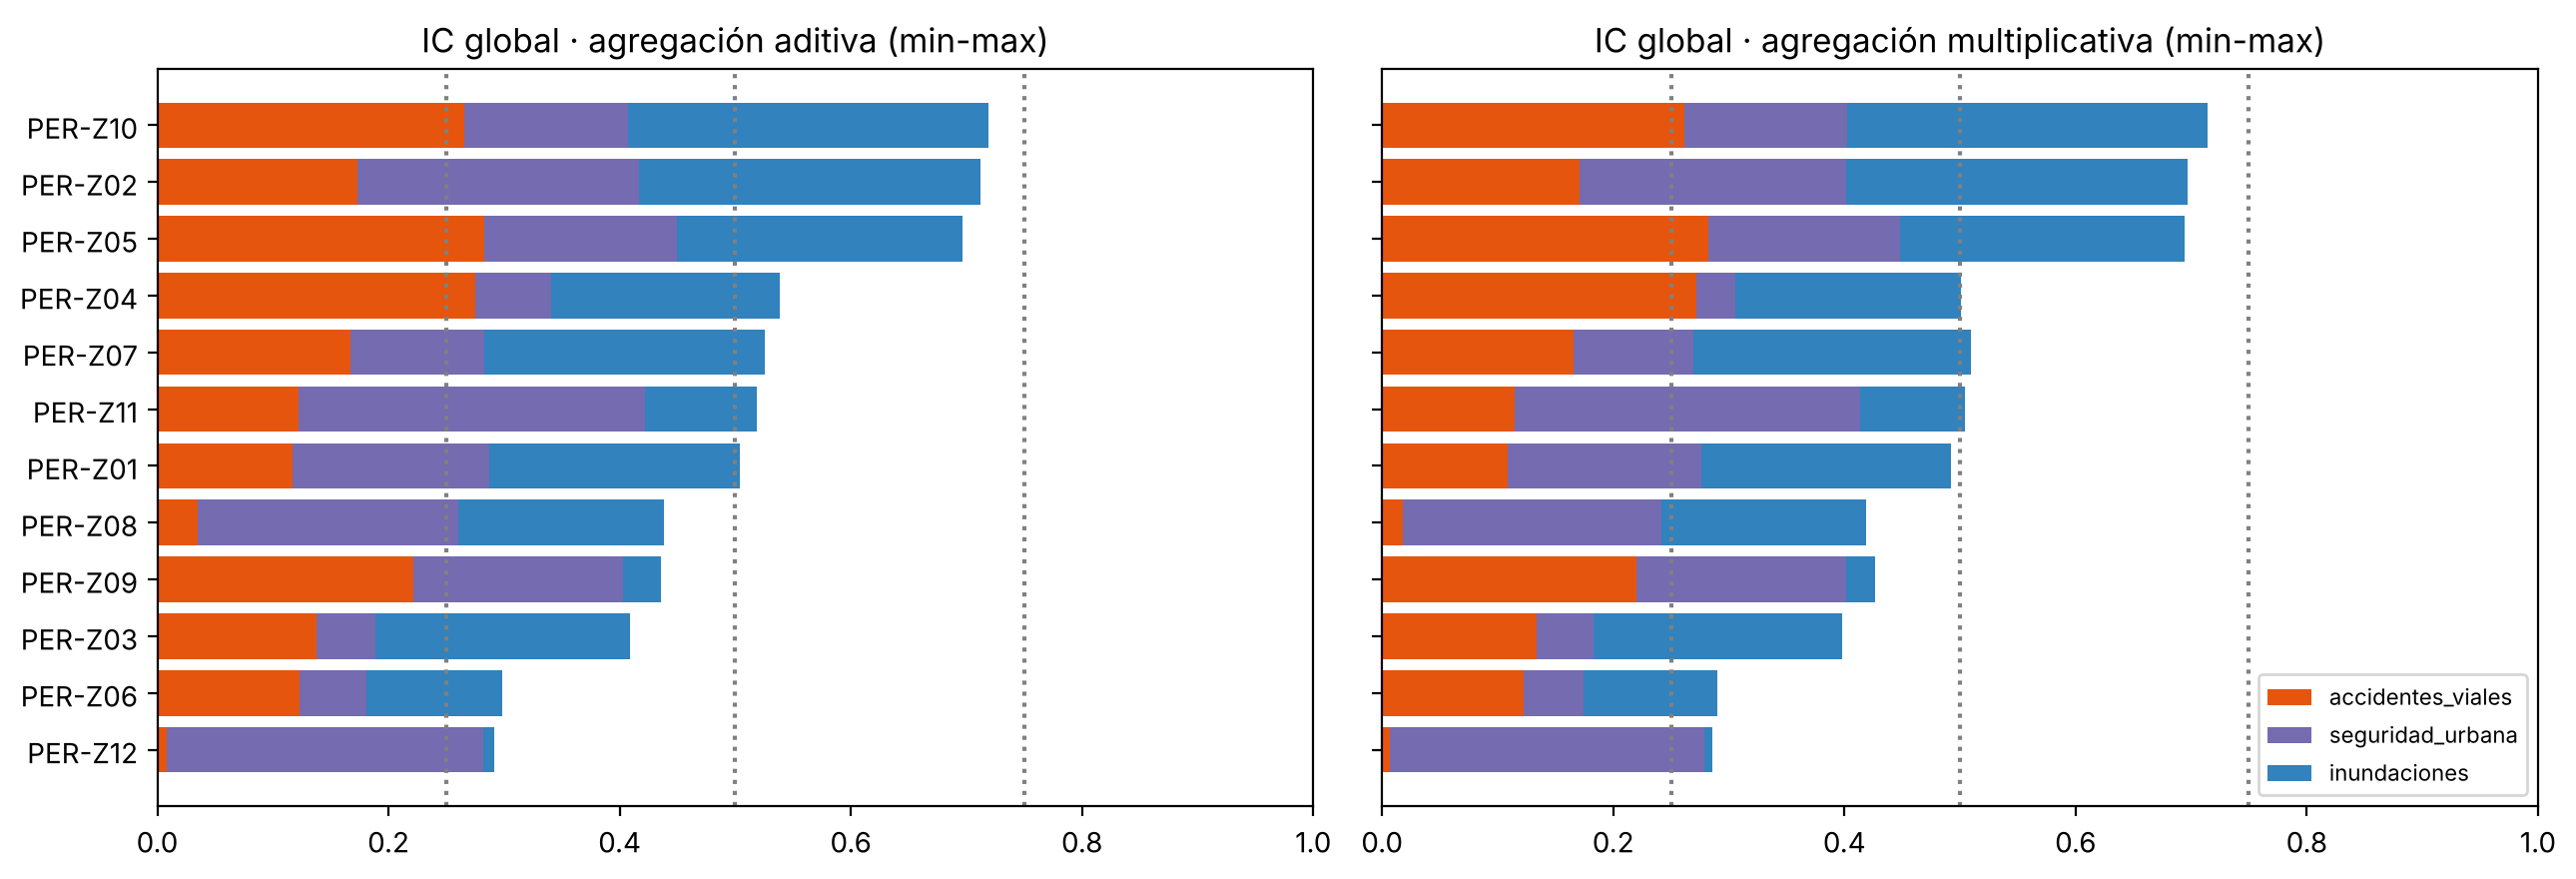

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
orden = tabla.index
for ax, rg in zip(axes, RIESGOS):
    C = COMP["minmax"]
    M = np.vstack([C.loc[orden, (rg, c)] for c in COMPS]).T
    im = ax.imshow(M, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(3), COMPS); ax.set_title(rg)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
axes[0].set_yticks(range(len(orden)), orden)
fig.colorbar(im, ax=axes, shrink=0.8, label="componente normalizado (min-max)")
fig.suptitle("Componentes H–E–V por zona y riesgo (zonas sintéticas, ordenadas por IC aditivo)")
plt.savefig(SALIDA_C / "urb03_componentes_hev.png", dpi=130, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, m in zip(axes, ["aditiva", "multiplicativa"]):
    R = RES[("minmax", m)].loc[orden]
    a = pd.Series(PESOS_BASE["alpha"])
    izq = np.zeros(len(R))
    for rg, col in zip(RIESGOS, ["#e6550d", "#756bb1", "#3182bd"]):
        contrib = a[rg] / a.sum() * R[rg]
        ax.barh(range(len(R)), contrib, left=izq, color=col, label=rg); izq += contrib
    for x_ in CORTES_NIVEL:
        ax.axvline(x_, ls=":", c="grey")
    ax.set_title(f"IC global · agregación {m} (min-max)"); ax.set_xlim(0, 1)
axes[0].set_yticks(range(len(orden)), orden); axes[0].invert_yaxis(); axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(SALIDA_C / "urb03_indice_global_comparacion.png", dpi=130); plt.show()

## C.5 · Análisis de sensibilidad de pesos (±10 %, ±20 %, ±30 %)

Se varía **un peso a la vez** (OAT), multiplicándolo por $1 \pm \delta$ y renormalizando para que la suma siga siendo 1. Se aplica a los tres pesos de componente ($w_H, w_E, w_V$) y a los tres pesos de riesgo ($\alpha_r$), con ambas agregaciones y normalización min-max.
Indicadores de estabilidad: Spearman con el ranking base, conservación del top-3 y máximo cambio de posición de una zona.

spearman_min  spearman_medio  pct_top3_conservado  \
agregacion     abs_delta                                                      
aditiva        10%               0.965           0.993                100.0   
               20%               0.958           0.984                100.0   
               30%               0.937           0.977                100.0   
multiplicativa 10%               0.972           0.987                100.0   
               20%               0.951           0.978                100.0   
               30%               0.937           0.974                100.0   

                          max_cambio_posicion  
agregacion     abs_delta                       
aditiva        10%                          2  
               20%                          2  
               30%                          3  
multiplicativa 10%                          2  
               20%                          2  
               30%                          2

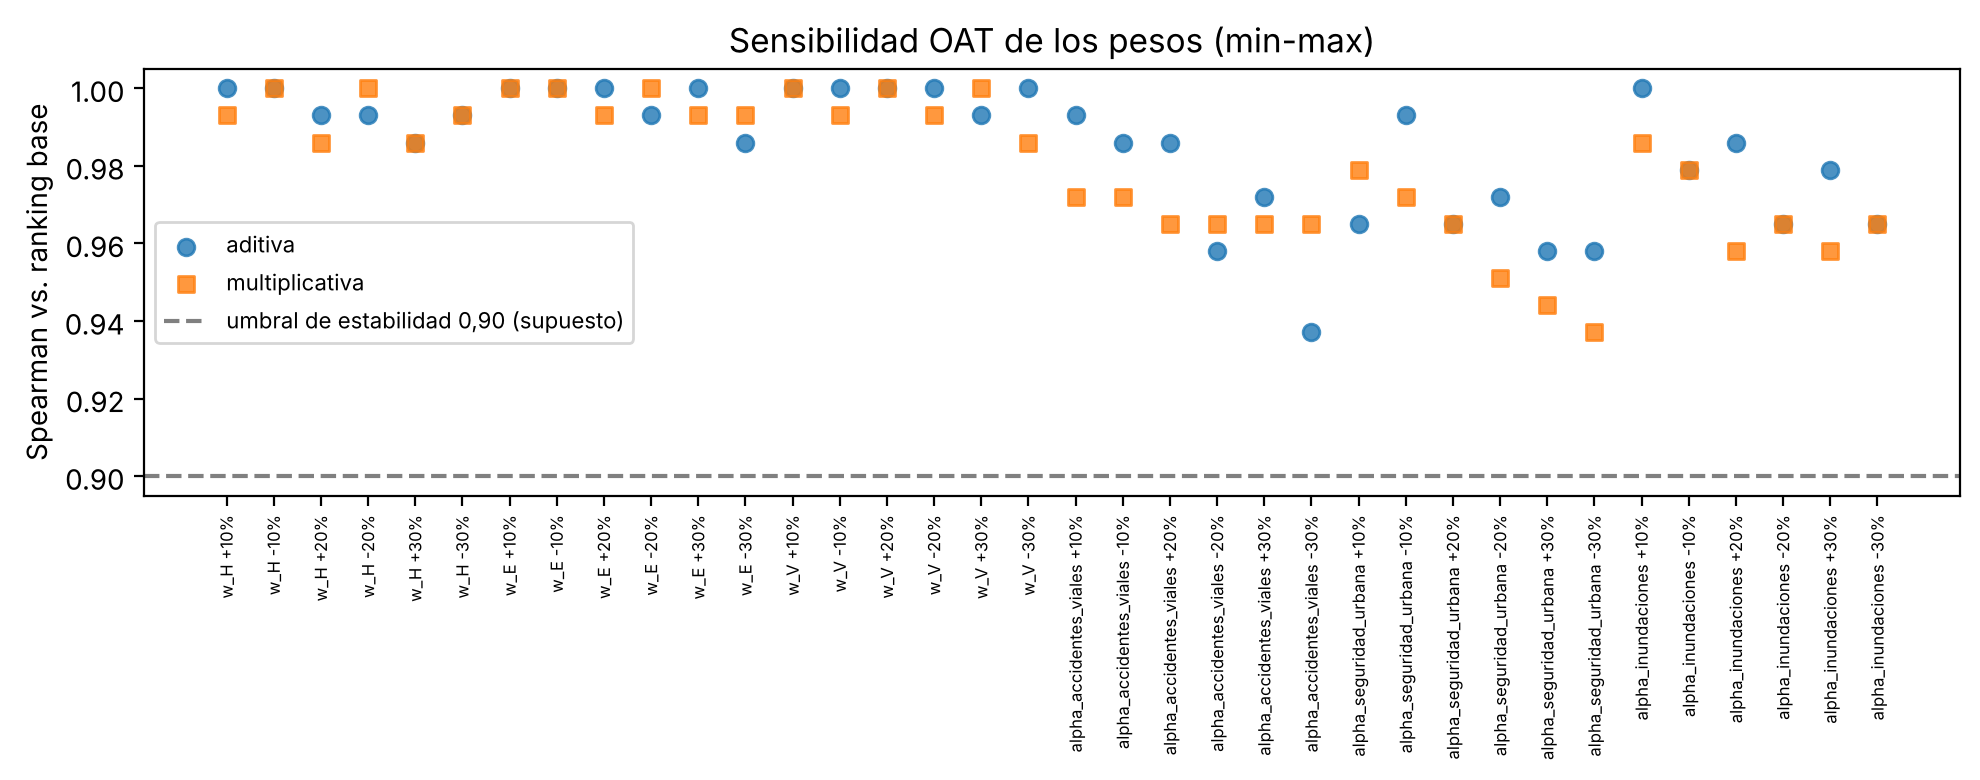

In [7]:
DELTAS = (0.10, 0.20, 0.30)

def sensibilidad(N, metodo):
    C = componentes(N)
    ref = indice(C, PESOS_BASE, metodo)["global"]
    filas = []
    for grupo, claves in [("w", COMPS), ("alpha", RIESGOS)]:
        for k in claves:
            for d in DELTAS:
                for signo in (+1, -1):
                    p = {"w": dict(PESOS_BASE["w"]), "alpha": dict(PESOS_BASE["alpha"])}
                    p[grupo][k] *= (1 + signo * d)
                    alt = indice(C, p, metodo)["global"]
                    filas.append({"agregacion": metodo, "peso": f"{grupo}_{k}", "delta": f"{signo * d:+.0%}",
                                  "spearman": spearmanr(ref, alt)[0],
                                  "top3_igual": set(ref.nlargest(3).index) == set(alt.nlargest(3).index),
                                  "max_cambio_posicion": int((ref.rank(ascending=False) - alt.rank(ascending=False)).abs().max())})
    return pd.DataFrame(filas)

SENS = pd.concat([sensibilidad(NORM["minmax"], m) for m in ["aditiva", "multiplicativa"]], ignore_index=True)
res_sens = (SENS.assign(abs_delta=SENS.delta.str.strip("+-"))
            .groupby(["agregacion", "abs_delta"])
            .agg(spearman_min=("spearman", "min"), spearman_medio=("spearman", "mean"),
                 pct_top3_conservado=("top3_igual", "mean"), max_cambio_posicion=("max_cambio_posicion", "max")).round(3))
res_sens["pct_top3_conservado"] = (100 * res_sens.pct_top3_conservado).round(0)
display(res_sens)

fig, ax = plt.subplots(figsize=(10, 4))
for m, mk in [("aditiva", "o"), ("multiplicativa", "s")]:
    s = SENS[SENS.agregacion == m]
    ax.scatter(s.peso + " " + s.delta, s.spearman, marker=mk, label=m, alpha=0.8)
ax.axhline(0.90, ls="--", c="grey", label="umbral de estabilidad 0,90 (supuesto)")
ax.set_ylabel("Spearman vs. ranking base"); ax.tick_params(axis="x", rotation=90, labelsize=6); ax.legend(fontsize=8)
ax.set_title("Sensibilidad OAT de los pesos (min-max)")
plt.tight_layout(); plt.savefig(SALIDA_C / "urb03_sensibilidad_pesos.png", dpi=130); plt.show()

## C.6 · Exportación: tabla de pesos, indicadores en formato del contrato y documento matemático

In [8]:
PESOS_TABLA = pd.DataFrame(
    [("w_H", "componente", "peligrosidad (H)", PESOS_BASE["w"]["H"]), ("w_E", "componente", "exposición (E)", PESOS_BASE["w"]["E"]),
     ("w_V", "componente", "vulnerabilidad (V)", PESOS_BASE["w"]["V"])] +
    [(f"alpha_{r}", "riesgo", r, PESOS_BASE["alpha"][r]) for r in RIESGOS] +
    [(f"peso_interno_{v.id_variable}", "variable", f"{v.riesgo}/{v.componente}",
      1 / ((MATRIZ.riesgo == v.riesgo) & (MATRIZ.componente == v.componente)).sum()) for v in MATRIZ.itertuples()],
    columns=["peso", "nivel", "aplica_a", "valor_base"])
PESOS_TABLA["valor_base"] = PESOS_TABLA.valor_base.round(4)
PESOS_TABLA["justificacion"] = np.where(PESOS_TABLA.nivel == "variable", "promedio simple dentro del componente",
                                        "neutral provisional (sin ponderación experta aún); ver sensibilidad")
PESOS_TABLA.to_csv(SALIDA_C / "urb03_tabla_pesos.csv", index=False, encoding="utf-8-sig")

filas = []
for (n, m), R in RES.items():
    for z in R.index:
        for rg in RIESGOS + ["global"]:
            filas.append({"id_zona": z, "periodo": "piloto", "riesgo": rg,
                          "H": None if rg == "global" else round(COMP[n].loc[z, (rg, "H")], 4),
                          "E": None if rg == "global" else round(COMP[n].loc[z, (rg, "E")], 4),
                          "V": None if rg == "global" else round(COMP[n].loc[z, (rg, "V")], 4),
                          "indice_criticidad": round(R.loc[z, rg], 4), "metodo_agregacion": m, "normalizacion": n,
                          "tipo_dato": TIPO_DATO})
IND = pd.DataFrame(filas)
IND["nivel"] = nivel(IND.indice_criticidad)
IND.to_csv(SALIDA_C / "urb03_indicadores_zona.csv", index=False, encoding="utf-8-sig")
SENS.to_csv(SALIDA_C / "urb03_sensibilidad_detalle.csv", index=False, encoding="utf-8-sig")
res_sens.to_csv(SALIDA_C / "urb03_sensibilidad_resumen.csv", encoding="utf-8-sig")
tabla.to_csv(SALIDA_C / "urb03_ranking_comparado.csv", encoding="utf-8-sig")

doc = f"""# URB-03 · Formulación del índice H–E–V (documento matemático)

Generado por `Indice_criticidad_urbana_Guayaquil_piloto_COMPLEMENTARIO.ipynb`, Parte C. Datos: {TIPO_DATO}, {len(X)} zonas.

## Definiciones
- Zonas: identificador común PER-Z## (COMUN/zonas_perimetral.geojson).
- Riesgos r: accidentes_viales, seguridad_urbana, inundaciones.
- Variables: {len(MATRIZ)} (COMUN/matriz_variables_hev.csv), cada una asignada a un riesgo y un componente H, E o V, con sentido + o −.

## Normalización
- N1 min-max: x' = (x − min) / (max − min)
- N2 z-score + Φ: x' = Φ((x − media) / desviación)
- Sentido −: x' ← 1 − x'

## Componentes
C(z, r) = promedio de x' de las variables del riesgo r y componente C ∈ {{H, E, V}}

## Agregación por riesgo (pesos w_H + w_E + w_V = 1)
- A, aditiva ponderada: R_A = w_H·H + w_E·E + w_V·V
- B, multiplicativa geométrica: R_B = max(H, ε)^w_H · max(E, ε)^w_E · max(V, ε)^w_V, con ε = {EPS}

## Índice global
IC(z) = Σ_r α_r · R(z, r), con Σ α_r = 1

## Niveles
bajo < 0,25 ≤ medio < 0,50 ≤ alto < 0,75 ≤ crítico

## Pesos base
w_H = w_E = w_V = 1/3; α_r = 1/3 (neutrales y provisionales).

## Resultados de la ejecución
- Spearman mínimo entre las 4 combinaciones de normalización y agregación: {rho.values.min():.3f}
- Spearman mínimo en la sensibilidad ±30 %: aditiva {SENS[(SENS.agregacion == 'aditiva') & SENS.delta.str.contains('30')].spearman.min():.3f}, multiplicativa {SENS[(SENS.agregacion == 'multiplicativa') & SENS.delta.str.contains('30')].spearman.min():.3f}
- Top-3 (aditiva, min-max): {', '.join(base['global'].nlargest(3).index)}
"""
(SALIDA_C / "urb03_formulacion_hev.md").write_text(doc, encoding="utf-8")
chequeos = {
    "≥ 5 zonas": len(X) >= 5,
    "Incluye los 3 riesgos": set(RIESGOS) <= set(MATRIZ.riesgo),
    "Índices en [0, 1]": bool(IND.indice_criticidad.between(0, 1).all()),
    "Dos agregaciones calculadas": IND.metodo_agregacion.nunique() == 2,
    "Sensibilidad con ±10/20/30 %": set(SENS.delta.str.strip("+-")) == {"10%", "20%", "30%"},
    "Resultados marcados como sintéticos": TIPO_DATO in ("sintetico", "mixto"),
}
display(pd.DataFrame({"chequeo": list(chequeos), "cumple": list(chequeos.values())}))
assert all(chequeos.values())
print(doc)

,chequeo,cumple
0,≥ 5 zonas,True
1,Incluye los 3 riesgos,True
2,"Índices en [0, 1]",True
3,Dos agregaciones calculadas,True
4,Sensibilidad con ±10/20/30 %,True
5,Resultados marcados como sintéticos,True


# URB-03 · Formulación del índice H–E–V (documento matemático)

Generado por `Indice_criticidad_urbana_Guayaquil_piloto_COMPLEMENTARIO.ipynb`, Parte C. Datos: sintetico, 12 zonas.

## Definiciones
- Zonas: identificador común PER-Z## (COMUN/zonas_perimetral.geojson).
- Riesgos r: accidentes_viales, seguridad_urbana, inundaciones.
- Variables: 19 (COMUN/matriz_variables_hev.csv), cada una asignada a un riesgo y un componente H, E o V, con sentido + o −.

## Normalización
- N1 min-max: x' = (x − min) / (max − min)
- N2 z-score + Φ: x' = Φ((x − media) / desviación)
- Sentido −: x' ← 1 − x'

## Componentes
C(z, r) = promedio de x' de las variables del riesgo r y componente C ∈ {H, E, V}

## Agregación por riesgo (pesos w_H + w_E + w_V = 1)
- A, aditiva ponderada: R_A = w_H·H + w_E·E + w_V·V
- B, multiplicativa geométrica: R_B = max(H, ε)^w_H · max(E, ε)^w_E · max(V, ε)^w_V, con ε = 0.01

## Índice global
IC(z) = Σ_r α_r · R(z, r), con Σ α_r = 1

## Niveles
bajo < 0,25 ≤ medio < 0,50 ≤ alto

## C.7 · Entregables y limitaciones

| Entregable mínimo (auditoría) | Archivo en `salidas_complementarias/` |
|---|---|
| Documento matemático | `urb03_formulacion_hev.md` (y la sección C.1 de este notebook) |
| Tabla de pesos | `urb03_tabla_pesos.csv` |
| Notebook reproducible | esta Parte C (semilla 42, sin dependencias externas) |
| Comparación de sensibilidad | `urb03_sensibilidad_resumen.csv`, `urb03_sensibilidad_detalle.csv`, `urb03_sensibilidad_pesos.png` |
| Resultados por zona (contrato `indicador_zona`) | `urb03_indicadores_zona.csv`, `urb03_ranking_comparado.csv` |

**Limitaciones:**
* Los valores son sintéticos. Los rankings sirven para comprobar la fórmula, **no** para priorizar zonas reales.
* Los pesos son neutrales y provisionales. Hace falta una ponderación experta (AHP o Delphi) antes de usar el índice para decidir.
* Con 12 zonas, la normalización min-max es sensible a los extremos. Por eso se compara con N2.

---
# Parte B · Notebook original (referencia)

Las celdas siguientes son una **copia del notebook original `Indice_criticidad_urbana_Guayaquil_piloto.ipynb`**. Se conservan para que el equipo
pueda comparar y reutilizar código, pero **no forman parte de la entrega mínima**: la entrega es la Parte C
(arriba). Las celdas de esta parte requieren las mismas dependencias y credenciales que el original
(OSM/Overpass, Supabase, API de LLM, etc.).

**Ajustes puntuales aplicados en esta copia** (marcados en el código con `# [AJUSTE AUDITORÍA]`):

* Celda de parámetros: `BBOX` pasa del área amplia de Guayaquil al **corredor de la Vía Perimetral**. La fórmula oficial de tres riesgos está en la Parte C.


# Índice geoespacial de criticidad urbana — Guayaquil
## Notebook piloto (prueba de concepto)

**Proyecto:** Índice geoespacial de criticidad urbana basado en peligrosidad, exposición y vulnerabilidad
**Institución:** Universidad de Guayaquil · Facultad de Ingeniería Industrial · Carrera de Sistemas de la Información
**Metodología:** CRISP-DM (las secciones del notebook siguen sus fases)

---

### ¿Qué hace este notebook?

Implementa, de punta a punta y con **datos sintéticos**, el flujo descrito en el anteproyecto:

| Paso | Contenido | Requisito del anteproyecto |
|---|---|---|
| 1–2 | Configuración y parámetros | — |
| 3 | Carga de datos (sintéticos, CSV o Supabase) | RF-01, RF-02, RF-03 |
| 4 | Cuadrícula de 500 × 500 m y *join* espacial | RF-04 |
| 5 | Agregación por unidad de análisis | — |
| 6 | Normalización (min-max y z-score) | RF-05 |
| 7 | Cálculo del índice de criticidad | RF-06 |
| 8 | Ranking y categorías por percentil | RF-07 |
| 9 | Análisis de sensibilidad (±10 %, ±20 %, ±30 %) con Spearman | RF-08, H3 |
| 10 | Autocorrelación espacial: Moran global, Gi\* y LISA | Sección 8.5 |
| 11 | Validación frente a puntos críticos y superposición vial–criminal | H1, H2 |
| 12 | Mapas estáticos e interactivos (Folium) | RF-09 |
| 13 | Exportación (archivos y Supabase) y registro de ejecución | RF-10, RF-11 |
| 14 | *Extensión opcional:* modelo predictivo base + informe con LLM | Borrador de datos |

> ⚠️ **Importante.** Todos los datos de este piloto son **ficticios**: se generan al azar para probar que el código funciona. Los mapas, rankings y correlaciones **no describen la realidad de Guayaquil** y no deben citarse como resultados. En la sección 3 se indica cómo reemplazarlos por los datos oficiales (ATM, Policía Nacional, INEC).

## 1. Comprensión del negocio (CRISP-DM · fase 1)

**Pregunta principal.** ¿Cómo combinar variables espaciales de siniestralidad vial y criminalidad para construir un índice geoespacial de criticidad urbana, interpretable y replicable?

**Marco conceptual.** La criticidad de cada zona se modela como una combinación de cuatro dimensiones:

- **Peligrosidad vial:** siniestros con lesionados y con fallecidos.
- **Peligrosidad criminal:** homicidios intencionales y robos.
- **Exposición:** densidad poblacional, puntos de interés (POIs) y flujo vehicular.
- **Vulnerabilidad:** pobreza, vivienda precaria, carencia de servicios básicos y población vulnerable (adultos mayores y menores).

**Unidad de análisis.** Celdas de 500 × 500 m (alternativa a los 67 circuitos de planificación policial, que se pueden cargar cuando se disponga de su geometría).

**Hipótesis que este notebook permite contrastar (con datos reales):**

- **H1:** las zonas de alta criticidad coinciden con puntos críticos conocidos.
- **H2:** existe superposición espacial entre siniestralidad vial y criminalidad.
- **H3:** el ranking es estable (Spearman alto) ante variaciones de ±20 % en los pesos.

## 2. Preparación del entorno y parámetros

Las librerías `geopandas`, `folium`, `scikit-learn` y `matplotlib` ya vienen en Colab. Solo se instalan `esda` y `libpysal` (estadística espacial).

In [ ]:
!pip -q install esda libpysal

In [ ]:
import warnings, logging, json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap
from shapely.geometry import box
from scipy.stats import spearmanr

from libpysal.weights import Queen
from esda.moran import Moran, Moran_Local, Moran_BV
from esda.getisord import G_Local

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

### 2.1 Parámetros del piloto

Todo lo que se pueda ajustar está concentrado en esta celda. **Los pesos son provisionales**: en el proyecto deben definirse y justificarse con el análisis multicriterio (objetivo específico 2).

In [ ]:
# --- Reproducibilidad -------------------------------------------------------
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# --- Sistemas de coordenadas ------------------------------------------------
CRS_GEO = "EPSG:4326"   # latitud / longitud (WGS84)
CRS_UTM = "EPSG:32717"  # UTM zona 17 Sur (metros) -> adecuado para Guayaquil

# --- Unidad de análisis -----------------------------------------------------
CELL_SIZE = 500                          # metros
# [AJUSTE AUDITORÍA] BBOX acotado al corredor de la Vía Perimetral (COMUN/zonas_perimetral.geojson).
# La formulación H–E–V oficial con los tres riesgos (incluye inundaciones) está en la Parte C.
BBOX = (-79.9600, -2.2425, -79.9100, -2.0730)    # (lon_min, lat_min, lon_max, lat_max)

# --- Origen de datos --------------------------------------------------------
USAR_DATOS_SINTETICOS = True   # False -> se usan datos reales (ver secciones 3.3 y 3.4)
FUENTE_REAL = "supabase"       # si USAR_DATOS_SINTETICOS=False: "supabase" o "csv"

# --- Tablas en Supabase (PostgreSQL) -----------------------------------------
TABLA_SINIESTROS = "nombreDetabla"        # <- reemplazar por el nombre real de tu tabla de accidentes
TABLA_DELITOS    = "delitos"
TABLA_CONTEXTO   = "contexto_celdas"
TABLA_PUNTOS     = "puntos_criticos"
TABLA_RANKING    = "ranking_criticidad"   # destino de los resultados (sección 13)
GUARDAR_EN_SUPABASE = False               # True -> sube el ranking al final del notebook
# Si tus columnas se llaman distinto, mapea {nombre_en_tu_tabla: nombre_esperado}
MAPA_COLUMNAS_SINIESTROS = {}             # ej.: {"latitud": "lat", "longitud": "lon", "heridos": "lesionados"}

# --- Pesos de las dimensiones (PROVISIONALES) -------------------------------
PESOS_DIM = {
    "peligrosidad_vial":     0.30,
    "peligrosidad_criminal": 0.30,
    "exposicion":            0.20,
    "vulnerabilidad":        0.20,
}

# --- Variables por dimensión (matriz de operacionalización, Tabla 2) --------
DIMENSIONES = {
    "peligrosidad_vial":     ["siniestros_lesionados", "siniestros_fallecidos"],
    "peligrosidad_criminal": ["homicidios", "robos"],
    "exposicion":            ["densidad_hab_km2", "pois", "flujo_veh_dia"],
    "vulnerabilidad":        ["pobreza_pct", "vivienda_precaria_pct", "sin_servicios_pct", "pob_vulnerable_pct"],
}
VARS_CONTEO = ["siniestros_lesionados", "siniestros_fallecidos", "homicidios", "robos", "pois"]
LOG_CONTEOS = True   # log(1+x) a los conteos antes de normalizar (reduce el efecto de valores extremos)

# --- Criterios de evaluación -----------------------------------------------
DELTAS = (0.10, 0.20, 0.30)    # variaciones de pesos para la sensibilidad
UMBRAL_SPEARMAN = 0.90         # supuesto del piloto para considerar "alta estabilidad"
PERMUTACIONES = 999            # permutaciones para pruebas de significancia espacial

# --- Salidas ----------------------------------------------------------------
OUT = Path("salidas_piloto"); OUT.mkdir(exist_ok=True)

logging.basicConfig(
    level=logging.INFO, force=True,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[logging.FileHandler(OUT / "ejecucion.log", mode="w", encoding="utf-8"), logging.StreamHandler()],
)
log = logging.getLogger("criticidad")
log.info("Parámetros: celda=%sm | pesos=%s | datos_sinteticos=%s", CELL_SIZE, PESOS_DIM, USAR_DATOS_SINTETICOS)

## 3. Comprensión y carga de datos (CRISP-DM · fases 2 y 3)

### 3.1 Estructura esperada de los datos

Para pasar de datos sintéticos a reales, cada fuente debe respetar estas columnas mínimas.

| Archivo | Fuente | Columnas mínimas |
|---|---|---|
| `siniestros.csv` | ATM / Observatorio de Movilidad | `fecha`, `lat`, `lon`, `lesionados`, `fallecidos` |
| `delitos.csv` | Policía Nacional / ECU911 | `fecha`, `lat`, `lon`, `tipo` (`homicidio`, `robo_persona`, `robo_domicilio`) |
| `contexto_celdas.csv` | INEC, GAD, OSM, ATM | `id_celda`, `densidad_hab_km2`, `pois`, `flujo_veh_dia`, `pobreza_pct`, `vivienda_precaria_pct`, `sin_servicios_pct`, `pob_vulnerable_pct` |
| `puntos_criticos.csv` | ATM / Policía | `nombre`, `lat`, `lon` |

Los datos del INEC suelen venir por sector o zona censal, no por celda; en el proyecto real habrá que **reasignarlos a la cuadrícula** (por ejemplo, ponderando por área de intersección).

### 3.2 Generador de datos sintéticos

Se simulan puntos de siniestros y delitos concentrados alrededor de centros ficticios, con **solape parcial** entre ambos para poder probar el análisis de superposición (H2).

In [ ]:
def generar_datos_sinteticos(n_vial=6000, n_crim=9000):
    # Devuelve siniestros, delitos y los centros ficticios de concentración.
    lon_min, lat_min, lon_max, lat_max = BBOX

    def centros(k):
        return np.column_stack([
            rng.uniform(lon_min + 0.015, lon_max - 0.015, k),
            rng.uniform(lat_min + 0.03,  lat_max - 0.03,  k),
        ])

    c_vial, c_crim = centros(5), centros(5)
    c_crim[:2] = c_vial[:2] + rng.normal(0, 0.004, (2, 2))   # 2 centros compartidos -> solape vial-criminal

    def puntos(n, cen, frac, sigma):
        n_c = int(n * frac)
        xy_c = cen[rng.integers(0, len(cen), n_c)] + rng.normal(0, sigma, (n_c, 2))
        xy_u = np.column_stack([rng.uniform(lon_min, lon_max, n - n_c), rng.uniform(lat_min, lat_max, n - n_c)])
        xy = np.vstack([xy_c, xy_u])
        xy[:, 0] = np.clip(xy[:, 0], lon_min, lon_max - 1e-6)
        xy[:, 1] = np.clip(xy[:, 1], lat_min, lat_max - 1e-6)
        return xy

    def fechas(n):  # 2023-01-01 a 2026-06-30
        return pd.Timestamp("2023-01-01") + pd.to_timedelta(rng.integers(0, 1277, n), unit="D")

    xy = puntos(n_vial, c_vial, 0.70, 0.006)
    vial = pd.DataFrame({"fecha": fechas(n_vial), "lat": xy[:, 1], "lon": xy[:, 0],
                         "lesionados": rng.poisson(1.2, n_vial), "fallecidos": rng.binomial(1, 0.07, n_vial)})

    xy = puntos(n_crim, c_crim, 0.75, 0.006)
    crim = pd.DataFrame({"fecha": fechas(n_crim), "lat": xy[:, 1], "lon": xy[:, 0],
                         "tipo": rng.choice(["homicidio", "robo_persona", "robo_domicilio"], n_crim, p=[0.12, 0.58, 0.30])})
    return vial, crim, c_vial, c_crim


def generar_contexto_sintetico(grid, c_crim):
    # Contexto por celda: la vulnerabilidad y la exposición aumentan cerca de los centros ficticios.
    cen = grid.geometry.centroid.to_crs(CRS_GEO)
    xy = np.column_stack([cen.x, cen.y])
    d = np.min(np.linalg.norm(xy[:, None, :] - c_crim[None, :, :], axis=2), axis=1)
    cerca = np.exp(-d / 0.03)
    n = len(grid)
    pct = lambda v: np.clip(v, 0, 100)
    return pd.DataFrame({
        "id_celda": grid["id_celda"].values,
        "densidad_hab_km2": np.clip(rng.normal(6000, 2500, n) + 9000 * cerca, 200, None),
        "pois": rng.poisson(3 + 25 * cerca),
        "flujo_veh_dia": np.clip(rng.normal(8000, 3000, n) + 12000 * cerca, 0, None),
        "pobreza_pct": pct(rng.normal(25, 8, n) + 30 * cerca),
        "vivienda_precaria_pct": pct(rng.normal(12, 6, n) + 25 * cerca),
        "sin_servicios_pct": pct(rng.normal(15, 7, n) + 25 * cerca),
        "pob_vulnerable_pct": pct(rng.normal(22, 4, n) + 6 * cerca),
    })

### 3.3 Carga de datos reales (opcional)

Si los datos están en archivos CSV, pon `USAR_DATOS_SINTETICOS = False` y `FUENTE_REAL = "csv"`, monta Google Drive y ajusta `RUTA_DATOS`. Si están en Supabase, ve a la sección 3.4.

In [ ]:
RUTA_DATOS = Path("/content/drive/MyDrive/criticidad_gye")   # carpeta con los CSV reales

def cargar_datos_csv():
    vial = pd.read_csv(RUTA_DATOS / "siniestros.csv", parse_dates=["fecha"])
    crim = pd.read_csv(RUTA_DATOS / "delitos.csv", parse_dates=["fecha"])
    contexto = pd.read_csv(RUTA_DATOS / "contexto_celdas.csv")
    puntos = pd.read_csv(RUTA_DATOS / "puntos_criticos.csv")
    # Validaciones básicas de calidad (el LLM y los modelos dependen de esto)
    for nombre, df, cols in [("siniestros", vial, ["fecha", "lat", "lon", "lesionados", "fallecidos"]),
                             ("delitos", crim, ["fecha", "lat", "lon", "tipo"])]:
        faltan = set(cols) - set(df.columns)
        assert not faltan, f"{nombre}: faltan columnas {faltan}"
        df.dropna(subset=["lat", "lon", "fecha"], inplace=True)
    return vial, crim, contexto, puntos

# Para usar datos de Drive, descomentar:
# from google.colab import drive; drive.mount("/content/drive")

### 3.4 Carga y guardado de datos en Supabase (PostgreSQL)

Supabase expone cada tabla de PostgreSQL mediante una API. Aquí se usa el cliente oficial (`supabase-py`) para **cargar** las tablas del proyecto y **guardar** los resultados.

**Antes de ejecutar:**

1. En Colab, panel izquierdo → 🔑 *Secretos*, crea `SUPABASE_URL` y `SUPABASE_KEY` y activa el acceso para este notebook. Así las credenciales **no quedan escritas en el código** (si compartes o subes el notebook a GitHub, no se filtran).
2. Usa la clave `anon` para **leer** (con una política de lectura en la tabla). Para **escribir** hace falta una política de inserción o la clave `service_role`; esta última da acceso total, así que trátala como contraseña y no la compartas.
3. Supabase devuelve por defecto **máximo 1000 filas por consulta**. La función de carga pagina automáticamente; sin eso, tus tablas de miles de registros quedarían truncadas sin ningún error.

In [ ]:
!pip -q install supabase

In [ ]:
import os
from supabase import create_client, Client

def _cliente_supabase() -> Client:
    # Lee las credenciales desde los Secretos de Colab (o variables de entorno).
    try:
        from google.colab import userdata
        url, key = userdata.get("SUPABASE_URL"), userdata.get("SUPABASE_KEY")
    except Exception:
        url, key = os.environ.get("SUPABASE_URL"), os.environ.get("SUPABASE_KEY")
    if not url or not key:
        raise RuntimeError("Faltan SUPABASE_URL / SUPABASE_KEY en los Secretos de Colab.")
    return create_client(url, key)


def cargar_tabla_supabase(tabla, tam_pagina=1000):
    # Equivale a SELECT * FROM tabla, trayendo todas las filas por páginas.
    cli, filas, desde = _cliente_supabase(), [], 0
    print(f"📡 Consultando Supabase: {tabla} ...")
    while True:
        r = cli.table(tabla).select("*").range(desde, desde + tam_pagina - 1).execute()
        filas.extend(r.data)
        if len(r.data) < tam_pagina:
            break
        desde += tam_pagina
    df = pd.DataFrame(filas)
    log.info("Supabase: %s -> %d filas", tabla, len(df))
    return df


def guardar_tabla_supabase(df, tabla, lote=500, columna_unica=None):
    # Inserta un DataFrame por lotes. Con columna_unica hace upsert (actualiza si ya existe).
    cli, d = _cliente_supabase(), df.copy()
    for c in d.select_dtypes(include=["datetime", "datetimetz"]).columns:
        d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%S")
    d = d.astype(object).where(d.notna(), None)            # NaN -> NULL; tipos compatibles con JSON
    registros = d.to_dict("records")
    for i in range(0, len(registros), lote):
        t = cli.table(tabla)
        if columna_unica:
            t.upsert(registros[i:i + lote], on_conflict=columna_unica).execute()
        else:
            t.insert(registros[i:i + lote]).execute()
    log.info("Supabase: %d filas guardadas en %s", len(registros), tabla)
    print(f"✅ {len(registros)} filas guardadas en '{tabla}'")


def cargar_datos_supabase():
    vial = cargar_tabla_supabase(TABLA_SINIESTROS).rename(columns=MAPA_COLUMNAS_SINIESTROS)
    crim = cargar_tabla_supabase(TABLA_DELITOS)
    contexto = cargar_tabla_supabase(TABLA_CONTEXTO)
    puntos = cargar_tabla_supabase(TABLA_PUNTOS)
    for nombre, df, cols in [("siniestros", vial, ["fecha", "lat", "lon", "lesionados", "fallecidos"]),
                             ("delitos", crim, ["fecha", "lat", "lon", "tipo"])]:
        faltan = set(cols) - set(df.columns)
        assert not faltan, f"{nombre}: faltan columnas {faltan}. Revisa MAPA_COLUMNAS_SINIESTROS o los nombres en Supabase."
        df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
        df.dropna(subset=["lat", "lon", "fecha"], inplace=True)
    return vial, crim, contexto, puntos


def cargar_datos_reales():
    return cargar_datos_supabase() if FUENTE_REAL == "supabase" else cargar_datos_csv()

**Prueba rápida de conexión** (solo la tabla de accidentes, para ver sus columnas antes de correr todo el flujo). Descomenta las líneas cuando tengas los secretos configurados:

In [ ]:
# df_accidentes = cargar_tabla_supabase(TABLA_SINIESTROS)
# display(df_accidentes.head()); print(df_accidentes.dtypes)

# Para SUBIR datos sintéticos de prueba a una tabla (la tabla debe existir con columnas compatibles):
# guardar_tabla_supabase(siniestros, "siniestros_prueba")

## 4. Cuadrícula de análisis y *join* espacial (RF-04)

Se trabaja en **UTM 17S (metros)** para que las celdas midan exactamente 500 × 500 m, y luego se vuelve a lat/lon solo para los mapas.

In [ ]:
def crear_cuadricula(bbox, size_m):
    minx, miny, maxx, maxy = gpd.GeoSeries([box(*bbox)], crs=CRS_GEO).to_crs(CRS_UTM).total_bounds
    xs, ys = np.arange(minx, maxx, size_m), np.arange(miny, maxy, size_m)
    celdas = [box(x, y, x + size_m, y + size_m) for x in xs for y in ys]
    return gpd.GeoDataFrame({"id_celda": np.arange(len(celdas))}, geometry=celdas, crs=CRS_UTM)

def a_geodf(df):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs=CRS_GEO).to_crs(CRS_UTM)

grid = crear_cuadricula(BBOX, CELL_SIZE)
log.info("Cuadrícula creada: %d celdas de %dx%d m", len(grid), CELL_SIZE, CELL_SIZE)

if USAR_DATOS_SINTETICOS:
    siniestros, delitos, c_vial, c_crim = generar_datos_sinteticos()
    contexto = generar_contexto_sintetico(grid, c_crim)
    # "Puntos críticos conocidos" ficticios: los centros de concentración
    puntos_criticos = pd.DataFrame({
        "nombre": [f"Punto vial {i+1}" for i in range(len(c_vial))] + [f"Punto criminal {i+1}" for i in range(len(c_crim))],
        "lon": np.r_[c_vial[:, 0], c_crim[:, 0]], "lat": np.r_[c_vial[:, 1], c_crim[:, 1]],
    })
else:
    siniestros, delitos, contexto, puntos_criticos = cargar_datos_reales()

print(f"Siniestros: {len(siniestros):,} | Delitos: {len(delitos):,} | Celdas: {len(grid):,}")
siniestros.head()

In [ ]:
# Join espacial: cada incidente se asigna a la celda que lo contiene
def asignar_celda(df):
    g = gpd.sjoin(a_geodf(df), grid[["id_celda", "geometry"]], how="inner", predicate="within")
    return pd.DataFrame(g.drop(columns=["geometry", "index_right"]))

sin_cel = asignar_celda(siniestros)
del_cel = asignar_celda(delitos)

perdidos_v, perdidos_d = len(siniestros) - len(sin_cel), len(delitos) - len(del_cel)
log.info("Join espacial: %d siniestros y %d delitos fuera de la cuadrícula", perdidos_v, perdidos_d)
print(f"Incidentes fuera del área de estudio -> siniestros: {perdidos_v} | delitos: {perdidos_d}")

## 5. Preparación de variables por celda (CRISP-DM · fase 3)

Se cuentan los incidentes por celda según las variables de la matriz de operacionalización.

> **Nota metodológica.** Una celda **sin registros** no significa **sin riesgo**: puede reflejar subregistro o falta de cobertura. Por eso se conserva todas las celdas (con 0) y se recomienda documentar la calidad de cada fuente (borrador de datos, sección *No olvidar*).

In [ ]:
conteos = pd.concat([
    sin_cel[sin_cel["lesionados"] > 0].groupby("id_celda").size().rename("siniestros_lesionados"),
    sin_cel[sin_cel["fallecidos"] > 0].groupby("id_celda").size().rename("siniestros_fallecidos"),
    del_cel[del_cel["tipo"] == "homicidio"].groupby("id_celda").size().rename("homicidios"),
    del_cel[del_cel["tipo"].isin(["robo_persona", "robo_domicilio"])].groupby("id_celda").size().rename("robos"),
], axis=1).reindex(grid["id_celda"]).fillna(0).astype(int)

tabla = (grid[["id_celda"]]
         .merge(conteos.reset_index(), on="id_celda", how="left")
         .merge(contexto, on="id_celda", how="left"))

# Control de calidad: valores faltantes en variables del índice
todas_vars = [v for lst in DIMENSIONES.values() for v in lst]
faltantes = tabla[todas_vars].isna().sum()
print("Valores faltantes por variable:"); print(faltantes[faltantes > 0] if faltantes.any() else "Ninguno")
tabla[todas_vars] = tabla[todas_vars].fillna(0)

tabla[todas_vars].describe().T.round(2)

## 6. Normalización (RF-05)

Las variables tienen unidades muy distintas (conteos, porcentajes, habitantes/km²). Se llevan a una escala común:

- **Min-max** (método principal): `x' = (x − mín) / (máx − mín)` → valores en [0, 1].
- **Z-score** (alternativa): `z = (x − media) / desviación` → útil para evaluar cuánto influye el método de normalización.

Para los conteos se aplica antes `log(1+x)` (parámetro `LOG_CONTEOS`), porque unas pocas celdas con muchos eventos aplastarían al resto.

In [ ]:
def normalizar(df, cols, metodo="minmax", log_conteos=LOG_CONTEOS):
    X = df[cols].astype(float).copy()
    if log_conteos:
        for c in cols:
            if c in VARS_CONTEO:
                X[c] = np.log1p(X[c])
    if metodo == "minmax":
        amp = (X.max() - X.min()).replace(0, np.nan)
        X = ((X - X.min()) / amp).fillna(0)
    elif metodo == "zscore":
        sd = X.std(ddof=0).replace(0, np.nan)
        X = ((X - X.mean()) / sd).fillna(0)
    else:
        raise ValueError("metodo debe ser 'minmax' o 'zscore'")
    return X

# Vista rápida del efecto de la normalización en una variable
ej = "robos"
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(tabla[ej], bins=30); ax[0].set_title(f"{ej} (original)")
ax[1].hist(normalizar(tabla, [ej], "minmax")[ej], bins=30); ax[1].set_title("min-max (con log)")
ax[2].hist(normalizar(tabla, [ej], "zscore")[ej], bins=30); ax[2].set_title("z-score (con log)")
plt.tight_layout(); plt.show()

## 7. Cálculo del índice de criticidad (RF-06)

Se calcula en dos niveles:

1. **Puntaje de cada dimensión** = media de sus variables normalizadas.
2. **Índice de criticidad** = media ponderada de las cuatro dimensiones:

$$IC_i = \sum_{d} w_d \cdot D_{d,i}, \qquad \sum_d w_d = 1$$

donde $D_{d,i}$ es el puntaje de la dimensión $d$ en la celda $i$.

In [ ]:
def calcular_indice(df, pesos, metodo="minmax"):
    out = pd.DataFrame({"id_celda": df["id_celda"].values})
    for dim, cols in DIMENSIONES.items():
        out[dim] = normalizar(df, cols, metodo).mean(axis=1).values
    w = pd.Series(pesos, dtype=float)
    w = w / w.sum()                                   # los pesos siempre suman 1
    out["indice_criticidad"] = sum(out[d] * w[d] for d in DIMENSIONES)
    return out

res = calcular_indice(tabla, PESOS_DIM, "minmax")
assert (res["id_celda"].values == grid["id_celda"].values).all()   # alineado con la cuadrícula
log.info("Índice calculado (min-max). Media=%.3f, máx=%.3f", res["indice_criticidad"].mean(), res["indice_criticidad"].max())
res.describe().round(3)

## 8. Ranking y categorías por percentil (RF-07)

| Categoría | Criterio |
|---|---|
| **Crítico** | percentil ≥ 90 |
| **Alto** | percentil 75–90 |
| **Medio** | percentil 50–75 |
| **Bajo** | percentil < 50 |

In [ ]:
def clasificar(s):
    p = s.rank(pct=True, method="average")
    return pd.cut(p, [0, 0.50, 0.75, 0.90, 1.0], labels=["Bajo", "Medio", "Alto", "Crítico"], include_lowest=True)

res["ranking"] = res["indice_criticidad"].rank(ascending=False, method="first").astype(int)
res["categoria"] = clasificar(res["indice_criticidad"])

# Se anexan los datos originales para interpretar cada celda
ranking = res.merge(tabla, on="id_celda").sort_values("ranking")
print(res["categoria"].value_counts().reindex(["Crítico", "Alto", "Medio", "Bajo"]))
ranking.head(10)[["ranking", "id_celda", "indice_criticidad", "categoria"] + list(DIMENSIONES)].round(3)

In [ ]:
# Comparación de métodos de normalización: ¿cambia el orden de las zonas?
res_z = calcular_indice(tabla, PESOS_DIM, "zscore")
rho_norm, _ = spearmanr(res["indice_criticidad"], res_z["indice_criticidad"])
print(f"Spearman entre índice min-max e índice z-score: {rho_norm:.3f}")
log.info("Spearman min-max vs z-score: %.3f", rho_norm)

## 9. Análisis de sensibilidad (RF-08 · hipótesis H3)

Se modifica el peso de **cada dimensión** en ±10 %, ±20 % y ±30 % (y se renormalizan los pesos para que sumen 1). Luego se compara el nuevo ranking con el original con el **coeficiente de Spearman**:

- ρ cercano a 1 → el orden de las zonas casi no cambia (índice robusto).
- Además se reporta qué porcentaje de las celdas del **10 % más crítico** se mantiene.

In [ ]:
def sensibilidad(df, pesos_base, deltas=DELTAS):
    base = calcular_indice(df, pesos_base)["indice_criticidad"]
    n_top = max(1, int(round(len(base) * 0.10)))
    top_base = set(base.nlargest(n_top).index)
    filas = []
    for dim in pesos_base:
        for d in deltas:
            for signo in (+1, -1):
                p = dict(pesos_base); p[dim] *= (1 + signo * d)
                nuevo = calcular_indice(df, p)["indice_criticidad"]
                rho, _ = spearmanr(base, nuevo)
                top = set(nuevo.nlargest(n_top).index)
                filas.append({"dimension": dim, "delta": d, "signo": "+" if signo > 0 else "-",
                              "spearman": rho, "top10_conservado": len(top & top_base) / n_top})
    return pd.DataFrame(filas)

sens = sensibilidad(tabla, PESOS_DIM)
resumen = sens.groupby("delta").agg(spearman_min=("spearman", "min"), spearman_medio=("spearman", "mean"),
                                    top10_min=("top10_conservado", "min")).round(3)
resumen

In [ ]:
# Detalle: Spearman por dimensión y variación
pivot = sens.assign(escenario=lambda d: d["signo"] + (d["delta"] * 100).astype(int).astype(str) + "%") \
            .pivot(index="dimension", columns="escenario", values="spearman")
orden = [f"{s}{int(d*100)}%" for d in DELTAS for s in ("-", "+")]
pivot = pivot[orden]

fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(pivot.values, cmap="YlGn", vmin=min(0.8, pivot.values.min()), vmax=1)
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden)
ax.set_yticks(range(len(pivot))); ax.set_yticklabels(pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman vs ranking base"); plt.colorbar(im); plt.tight_layout(); plt.show()

rho_min_20 = sens.loc[np.isclose(sens["delta"], 0.20), "spearman"].min()
veredicto = "SE CUMPLE" if rho_min_20 >= UMBRAL_SPEARMAN else "NO se cumple"
print(f"H3 (piloto): Spearman mínimo con ±20 % = {rho_min_20:.3f} -> {veredicto} el umbral de {UMBRAL_SPEARMAN}")
log.info("H3: spearman_min(±20%%)=%.3f umbral=%.2f", rho_min_20, UMBRAL_SPEARMAN)

## 10. Análisis espacial: Moran global, Gi\* y LISA (sección 8.5 del anteproyecto)

- **Moran global:** resume si la criticidad tiende a agruparse (I > 0), dispersarse (I < 0) o ser aleatoria.
- **Getis-Ord Gi\*:** detecta *hotspots* y *coldspots* estadísticamente significativos.
- **Moran local (LISA):** clasifica cada celda como alto-alto (HH), bajo-bajo (LL) o atípica (HL, LH).

Se usan vecinos tipo **Queen** (celdas que comparten borde o vértice) con pesos estandarizados por fila.

In [ ]:
w = Queen.from_dataframe(grid, use_index=False)
w.transform = "r"
y = res["indice_criticidad"].values

mi = Moran(y, w, permutations=PERMUTACIONES)
print(f"Moran global I = {mi.I:.3f} | p (simulado) = {mi.p_sim:.4f}")

gi = G_Local(y, w, transform="R", star=True, permutations=PERMUTACIONES, seed=SEED)
res["hotspot_gi"] = np.select(
    [(gi.p_sim < 0.05) & (gi.Zs > 0), (gi.p_sim < 0.05) & (gi.Zs < 0)],
    ["Hotspot", "Coldspot"], default="No significativo")

lisa = Moran_Local(y, w, permutations=PERMUTACIONES, seed=SEED)
etiquetas = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
res["lisa"] = [etiquetas[q] if p < 0.05 else "No significativo" for q, p in zip(lisa.q, lisa.p_sim)]

log.info("Moran I=%.3f (p=%.4f) | hotspots Gi*=%d", mi.I, mi.p_sim, (res["hotspot_gi"] == "Hotspot").sum())
print(res["hotspot_gi"].value_counts().to_string())
print(res["lisa"].value_counts().to_string())

## 11. Validación y evaluación de hipótesis (CRISP-DM · fase 5)

### 11.1 H1 — Coincidencia con puntos críticos conocidos

Se verifica qué proporción de los puntos críticos conocidos cae dentro del 10 % y del 25 % de celdas con mayor criticidad. Como referencia, **al azar** se esperaría 10 % y 25 %, respectivamente.

In [ ]:
pc = gpd.sjoin(a_geodf(puntos_criticos), grid[["id_celda", "geometry"]], how="inner", predicate="within")
ids_pc = pc["id_celda"].unique()

def tasa_acierto(ids, q):
    umbral = res["indice_criticidad"].quantile(1 - q)
    top = set(res.loc[res["indice_criticidad"] >= umbral, "id_celda"])
    return np.mean([i in top for i in ids])

h1 = pd.DataFrame({"zona_considerada": ["Top 10 %", "Top 25 %"],
                   "aciertos": [tasa_acierto(ids_pc, 0.10), tasa_acierto(ids_pc, 0.25)],
                   "esperado_al_azar": [0.10, 0.25]}).round(3)
print(f"Puntos críticos ubicados en la cuadrícula: {len(ids_pc)}")
h1

### 11.2 H2 — Superposición espacial entre siniestralidad vial y criminalidad

Se miden dos cosas: la correlación de Spearman entre ambas dimensiones y el **Moran bivariado** (¿las celdas con alta peligrosidad vial están rodeadas de celdas con alta peligrosidad criminal?).

In [ ]:
rho_vc, p_vc = spearmanr(res["peligrosidad_vial"], res["peligrosidad_criminal"])
mbv = Moran_BV(res["peligrosidad_vial"].values, res["peligrosidad_criminal"].values, w, permutations=PERMUTACIONES)

print(f"Spearman (vial vs criminal): {rho_vc:.3f} (p = {p_vc:.2g})")
print(f"Moran bivariado: I = {mbv.I:.3f} (p simulado = {mbv.p_sim:.4f})")
log.info("H2: spearman=%.3f | moran_bv=%.3f (p=%.4f)", rho_vc, mbv.I, mbv.p_sim)

## 12. Visualización (RF-09)

### 12.1 Mapa estático

In [ ]:
mapa = grid.merge(res, on="id_celda")

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
mapa.plot(column="indice_criticidad", cmap="YlOrRd", legend=True, ax=axes[0],
          legend_kwds={"shrink": 0.6, "label": "Índice de criticidad"})
axes[0].set_title("Índice de criticidad (piloto, datos sintéticos)")

colores = {"Hotspot": "#d7301f", "Coldspot": "#2b8cbe", "No significativo": "#eeeeee"}
mapa.plot(color=mapa["hotspot_gi"].map(colores), ax=axes[1], edgecolor="none")
axes[1].set_title("Hotspots / coldspots (Gi*, p < 0.05)")
for a in axes: a.set_axis_off()
plt.tight_layout(); plt.savefig(OUT / "mapa_estatico.png", bbox_inches="tight"); plt.show()

### 12.2 Mapa interactivo (Folium)

Incluye la capa de criticidad por celda, un mapa de calor y los puntos críticos conocidos. Se puede activar/desactivar cada capa desde el control superior derecho.

In [ ]:
mapa_ll = mapa.to_crs(CRS_GEO)
mapa_ll["indice_r"] = mapa_ll["indice_criticidad"].round(3)
centro = [(BBOX[1] + BBOX[3]) / 2, (BBOX[0] + BBOX[2]) / 2]

m = folium.Map(location=centro, zoom_start=11, tiles="cartodbpositron")

folium.Choropleth(
    geo_data=mapa_ll[["id_celda", "geometry"]].to_json(), data=mapa_ll, columns=["id_celda", "indice_criticidad"],
    key_on="feature.properties.id_celda", fill_color="YlOrRd", fill_opacity=0.7, line_opacity=0.05,
    legend_name="Índice de criticidad", name="Criticidad por celda",
).add_to(m)

folium.GeoJson(
    mapa_ll[["id_celda", "indice_r", "categoria", "ranking", "hotspot_gi", "geometry"]].astype({"categoria": str}).to_json(),
    name="Detalle (tooltip)", style_function=lambda f: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(fields=["id_celda", "ranking", "indice_r", "categoria", "hotspot_gi"],
                                  aliases=["Celda", "Ranking", "Índice", "Categoría", "Gi*"]),
).add_to(m)

cen = mapa_ll.geometry.centroid
HeatMap(list(zip(cen.y, cen.x, mapa_ll["indice_criticidad"])), radius=18, blur=22, name="Mapa de calor").add_to(m)

fg = folium.FeatureGroup(name="Puntos críticos conocidos (ficticios)")
for _, r in puntos_criticos.iterrows():
    folium.CircleMarker([r["lat"], r["lon"]], radius=5, color="#08519c", fill=True, tooltip=r["nombre"]).add_to(fg)
fg.add_to(m)

folium.LayerControl().add_to(m)
m.save(OUT / "mapa_interactivo.html")
m

## 13. Exportación y registro de ejecución (RF-10, RF-11)

In [ ]:
ranking.to_csv(OUT / "ranking_criticidad.csv", index=False, encoding="utf-8-sig")
sens.to_csv(OUT / "sensibilidad.csv", index=False)
mapa_ll.drop(columns=["indice_r"]).astype({"categoria": str}).to_file(OUT / "criticidad.geojson", driver="GeoJSON")

log.info("Exportados: ranking_criticidad.csv, sensibilidad.csv, criticidad.geojson, mapa_interactivo.html, mapa_estatico.png")
print("Archivos generados en", OUT.resolve())
for f in sorted(OUT.iterdir()): print(" -", f.name, f"({f.stat().st_size/1024:.0f} KB)")

# Subir el ranking a Supabase (activar GUARDAR_EN_SUPABASE = True en los parámetros)
if GUARDAR_EN_SUPABASE:
    cols_subir = ["id_celda", "ranking", "indice_criticidad", "categoria"] + list(DIMENSIONES)
    guardar_tabla_supabase(ranking[cols_subir].astype({"categoria": str}), TABLA_RANKING, columna_unica="id_celda")

# Para descargar todo en Colab:
# import shutil; shutil.make_archive("salidas_piloto", "zip", OUT)
# from google.colab import files; files.download("salidas_piloto.zip")

## 14. Extensión opcional: modelo predictivo base + informe con LLM

El **borrador de datos** propone una arquitectura híbrida: modelos de aprendizaje automático hacen la predicción y el LLM solo **explica** resultados. Esta sección es un esqueleto mínimo de esa idea; **no forma parte del alcance del índice** del anteproyecto, y sirve para probar el flujo.

> **Regla de oro:** el LLM no inventa probabilidades ni sustituye al modelo estadístico. Solo recibe cifras ya calculadas y las redacta.

### 14.1 Modelo predictivo base (Random Forest)

Se predice el número de delitos del **mes siguiente** en cada celda, usando rezagos mensuales y variables de contexto, con **división temporal** (se entrena con el pasado y se evalúa con el futuro).

⚠️ Los datos sintéticos no tienen dinámica temporal (las fechas son aleatorias), así que aquí el modelo aprenderá casi solo el patrón espacial. Con datos reales, la parte temporal será informativa.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Panel celda x mes (se conservan los meses sin eventos como 0)
delitos_p = del_cel.copy()
delitos_p["mes"] = delitos_p["fecha"].dt.to_period("M").dt.to_timestamp()
meses = pd.date_range(delitos_p["mes"].min(), delitos_p["mes"].max(), freq="MS")
idx = pd.MultiIndex.from_product([grid["id_celda"], meses], names=["id_celda", "mes"])
panel = (delitos_p.groupby(["id_celda", "mes"]).size().rename("n_delitos")
         .reindex(idx, fill_value=0).reset_index().sort_values(["id_celda", "mes"]))

g = panel.groupby("id_celda")["n_delitos"]
panel["lag1"], panel["lag2"], panel["lag3"] = g.shift(1), g.shift(2), g.shift(3)
panel["media3"] = panel[["lag1", "lag2", "lag3"]].mean(axis=1)
panel["objetivo"] = g.shift(-1)                              # delitos del mes siguiente
panel["mes_sin"] = np.sin(2 * np.pi * panel["mes"].dt.month / 12)
panel["mes_cos"] = np.cos(2 * np.pi * panel["mes"].dt.month / 12)

estaticas = res[["id_celda", "exposicion", "vulnerabilidad", "peligrosidad_vial"]]
panel = panel.merge(estaticas, on="id_celda").dropna()

FEATURES = ["lag1", "lag2", "lag3", "media3", "mes_sin", "mes_cos", "exposicion", "vulnerabilidad", "peligrosidad_vial"]
CORTE = pd.Timestamp("2025-12-01")                           # entrenamiento < CORTE <= prueba
train, test = panel[panel["mes"] < CORTE], panel[panel["mes"] >= CORTE]
print(f"Entrenamiento: {len(train):,} filas | Prueba: {len(test):,} filas")

rf = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf.fit(train[FEATURES], train["objetivo"])
pred = rf.predict(test[FEATURES])

mae_rf = mean_absolute_error(test["objetivo"], pred)
mae_base = mean_absolute_error(test["objetivo"], test["media3"])
print(f"MAE Random Forest: {mae_rf:.3f} | MAE línea base (media 3 meses): {mae_base:.3f}")

# ¿El modelo detecta las celdas con más delitos? (10 % superior)
agg = test.assign(pred=pred).groupby("id_celda").agg(real=("objetivo", "sum"), pred=("pred", "sum"))
k = max(1, int(len(agg) * 0.10))
recall_k = len(set(agg["real"].nlargest(k).index) & set(agg["pred"].nlargest(k).index)) / k
print(f"Coincidencia del top 10 % predicho con el top 10 % real: {recall_k:.2%}")

pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(6, 3), title="Importancia de variables (RF)")
plt.tight_layout(); plt.show()
# Para probar XGBoost: from xgboost import XGBRegressor y reemplazar el modelo (misma interfaz fit/predict).

### 14.2 Informe explicativo con LLM

Se construye un *prompt* con **hechos ya calculados** (ranking, dimensiones, hotspots, predicción) y se le pide al LLM que redacte un informe breve **sin añadir cifras**. Si no hay clave de API configurada, se genera un informe de plantilla con las mismas cifras, de modo que la celda funciona igualmente.

Para usar el LLM real: en Colab, panel izquierdo → 🔑 *Secretos* → crear `ANTHROPIC_API_KEY` y darle acceso al notebook.

In [ ]:
MODELO_LLM = "claude-sonnet-5-5"   # ajustar según el modelo disponible en la cuenta

pred_celda = agg["pred"].rename("pred_delitos_prox_meses")
top3 = ranking.head(3).merge(pred_celda, left_on="id_celda", right_index=True, how="left")
top3 = top3.merge(res[["id_celda", "hotspot_gi", "lisa"]], on="id_celda")

def hechos_celda(r):
    return {"celda": int(r.id_celda), "ranking": int(r.ranking), "indice_criticidad": round(float(r.indice_criticidad), 3),
            "categoria": str(r.categoria),
            "dimensiones": {d: round(float(r[d]), 3) for d in DIMENSIONES},
            "hotspot_gi": r.hotspot_gi, "lisa": r.lisa,
            "delitos_previstos_periodo_prueba": None if pd.isna(r.pred_delitos_prox_meses) else round(float(r.pred_delitos_prox_meses), 1)}

hechos = [hechos_celda(r) for _, r in top3.iterrows()]

SISTEMA = ("Eres un analista de riesgo urbano que redacta para autoridades municipales. Usa EXCLUSIVAMENTE las cifras del JSON. "
           "No inventes probabilidades, causas ni cifras. Si un dato es nulo, dilo. Indica que los datos del piloto son sintéticos si así se señala. "
           "Redacta en español, máximo 180 palabras, con una recomendación de verificación en campo por celda.")
PROMPT = ("Datos del piloto (SINTÉTICOS, no reales). Redacta un informe breve sobre las 3 celdas más críticas:\n"
          + json.dumps(hechos, ensure_ascii=False, indent=2))

def informe_plantilla(hechos):
    lineas = ["INFORME (plantilla sin LLM) — datos sintéticos de prueba"]
    for h in hechos:
        dom = max(h["dimensiones"], key=h["dimensiones"].get)
        lineas.append(f"- Celda {h['celda']}: puesto {h['ranking']}, índice {h['indice_criticidad']} ({h['categoria']}). "
                      f"Dimensión dominante: {dom}. Gi*: {h['hotspot_gi']}. Verificar en campo.")
    return "\n".join(lineas)

def informe_llm(prompt):
    try:
        from google.colab import userdata
        import anthropic
        cliente = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))
        msg = cliente.messages.create(model=MODELO_LLM, max_tokens=600, system=SISTEMA,
                                      messages=[{"role": "user", "content": prompt}])
        return msg.content[0].text
    except Exception as e:
        log.warning("LLM no disponible (%s). Se usa plantilla.", type(e).__name__)
        return None

# Si se quiere el LLM real: !pip -q install anthropic  y configurar el secreto.
texto = informe_llm(PROMPT) or informe_plantilla(hechos)
print(texto)
(OUT / "informe_top3.txt").write_text(texto, encoding="utf-8")

## 15. Resumen y siguientes pasos

### Cumplimiento de requisitos funcionales en este piloto

| ID | Requisito | Estado |
|---|---|---|
| RF-01 a RF-03 | Carga de datos viales, criminales y contextuales | ✅ (sintéticos; plantilla para datos reales) |
| RF-04 | Georreferenciación con *join* espacial | ✅ |
| RF-05 | Normalización min-max y z-score | ✅ |
| RF-06 | Índice como media ponderada de dimensiones | ✅ |
| RF-07 | Ranking con percentiles | ✅ |
| RF-08 | Sensibilidad ±10/20/30 % con Spearman | ✅ |
| RF-09 | Mapas interactivos (Folium) y de calor | ✅ |
| RF-10 | Exportación CSV, GeoJSON y HTML | ✅ |
| RF-11 | Registro de ejecución | ✅ (`ejecucion.log`) |

### De piloto a proyecto real

1. **Datos reales:** solicitar/descargar siniestros (ATM), delitos (Policía Nacional/ECU911) y variables del INEC; verificar la cobertura 2023–2026 y reasignar los datos censales a la cuadrícula.
2. **Unidad de análisis:** probar también con los 67 circuitos policiales y comparar resultados con la cuadrícula.
3. **Pesos:** reemplazar los pesos provisionales por los definidos en el análisis multicriterio, y documentar la justificación.
4. **Etapas CRISP-DM del anteproyecto:** primero un subconjunto (2025), luego 2023–2026 completo y, por último, refinamiento.
5. **Empaquetado:** pasar las funciones de este notebook al módulo `risk_index.py` (alcance del proyecto) y versionarlo en GitHub.
6. **Calidad de datos:** documentar procedencia, unidad y subregistro por variable; recordar que ausencia de registros no es ausencia de riesgo.
7. **Fuera del alcance del anteproyecto:** dashboard completo, tiempo real con ECU911 y despliegue institucional (la sección 14 es solo una exploración opcional).